In [8]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Create project folder
!mkdir -p "/content/drive/MyDrive/fraud_detection_project/data"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
# Create folders for our project
import os

# Create main project folder
os.makedirs('/content/drive/MyDrive/fraud_detection_project', exist_ok=True)
os.makedirs('/content/drive/MyDrive/fraud_detection_project/data', exist_ok=True)
os.makedirs('/content/drive/MyDrive/fraud_detection_project/notebooks', exist_ok=True)
os.makedirs('/content/drive/MyDrive/fraud_detection_project/reports', exist_ok=True)
os.makedirs('/content/drive/MyDrive/fraud_detection_project/results', exist_ok=True)

print("✅ Project folders created!")
print("\nYour project structure:")
print("fraud_detection_project/")
print("  ├── data/")
print("  ├── notebooks/")
print("  ├── reports/")
print("  └── results/")

✅ Project folders created!

Your project structure:
fraud_detection_project/
  ├── data/
  ├── notebooks/
  ├── reports/
  └── results/


In [10]:
# Check if files are there
import os

data_path = '/content/drive/MyDrive/fraud_detection_project/data/'
files = os.listdir(data_path)

print("Files in data folder:")
for f in files:
    print(f"  ✓ {f}")

Files in data folder:
  ✓ Train_Beneficiarydata.csv
  ✓ Train_Outpatientdata.csv
  ✓ Train_labels.csv
  ✓ Train_Inpatientdata.csv
  ✓ processed_data.csv


In [11]:
# Install all libraries we need
!pip install imbalanced-learn xgboost -q

print("✅ Libraries installed!")

✅ Libraries installed!


In [12]:
# Import all libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Settings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
plt.style.use('default')
sns.set_palette("husl")

print("✅ All libraries imported!")
print("\nLibraries loaded:")
print("  • pandas (data manipulation)")
print("  • numpy (numerical operations)")
print("  • matplotlib (plotting)")
print("  • seaborn (beautiful plots)")

✅ All libraries imported!

Libraries loaded:
  • pandas (data manipulation)
  • numpy (numerical operations)
  • matplotlib (plotting)
  • seaborn (beautiful plots)


In [13]:
# Check if files are there
import os

data_path = '/content/drive/MyDrive/fraud_detection_project/data/'
files = os.listdir(data_path)

print("Files in data folder:")
for f in files:
    print(f"  ✓ {f}")

Files in data folder:
  ✓ Train_Beneficiarydata.csv
  ✓ Train_Outpatientdata.csv
  ✓ Train_labels.csv
  ✓ Train_Inpatientdata.csv
  ✓ processed_data.csv


In [14]:
# Load all 4 datasets
print("📂 Loading datasets...")

# Define file paths
data_path = '/content/drive/MyDrive/fraud_detection_project/data/'

# --- Start of added code to fix FileNotFoundError ---
import shutil
import os

source_dir = '/content/'
target_dir = data_path

# Ensure target directory exists (already done by an earlier cell, but good to be safe)
os.makedirs(target_dir, exist_ok=True)

print("Copying data files to project data directory...")
files_to_copy = {
    'Train_Beneficiarydata-1542865627584.csv': 'Train_Beneficiarydata.csv',
    'Train_Inpatientdata-1542865627584.csv': 'Train_Inpatientdata.csv',
    'Train_Outpatientdata-1542865627584.csv': 'Train_Outpatientdata.csv',
    'Train-1542865627584.csv': 'Train_labels.csv' # Assuming Train.csv is the labels file
}

for src_name, dest_name in files_to_copy.items():
    src_path = os.path.join(source_dir, src_name)
    dest_path = os.path.join(target_dir, dest_name)
    if os.path.exists(src_path):
        shutil.copy(src_path, dest_path)
        print(f"  ✓ Copied {src_name} to {dest_path}")
    else:
        print(f"  ⚠️ Warning: Source file not found: {src_path}")
print("Finished copying data files.\n")
# --- End of added code ---


# Load each file
beneficiary = pd.read_csv(data_path + 'Train_Beneficiarydata.csv')
inpatient = pd.read_csv(data_path + 'Train_Inpatientdata.csv')
outpatient = pd.read_csv(data_path + 'Train_Outpatientdata.csv')
labels = pd.read_csv(data_path + 'Train_labels.csv')

print("✅ All datasets loaded successfully!\n")

# Show what we loaded
print("="*60)
print("DATASET SUMMARY")
print("="*60)
print(f"1. Beneficiary Data: {beneficiary.shape[0]:,} rows × {beneficiary.shape[1]} columns")
print(f"2. Inpatient Data:   {inpatient.shape[0]:,} rows × {inpatient.shape[1]} columns")
print(f"3. Outpatient Data:  {outpatient.shape[0]:,} rows × {outpatient.shape[1]} columns")
print(f"4. Labels Data:      {labels.shape[0]:,} rows × {labels.shape[1]} columns")
print("="*60)

📂 Loading datasets...
Copying data files to project data directory...
  ✓ Copied Train_Beneficiarydata-1542865627584.csv to /content/drive/MyDrive/fraud_detection_project/data/Train_Beneficiarydata.csv
  ✓ Copied Train_Inpatientdata-1542865627584.csv to /content/drive/MyDrive/fraud_detection_project/data/Train_Inpatientdata.csv
  ✓ Copied Train_Outpatientdata-1542865627584.csv to /content/drive/MyDrive/fraud_detection_project/data/Train_Outpatientdata.csv
  ✓ Copied Train-1542865627584.csv to /content/drive/MyDrive/fraud_detection_project/data/Train_labels.csv
Finished copying data files.

✅ All datasets loaded successfully!

DATASET SUMMARY
1. Beneficiary Data: 138,556 rows × 25 columns
2. Inpatient Data:   40,474 rows × 30 columns
3. Outpatient Data:  517,737 rows × 27 columns
4. Labels Data:      5,410 rows × 2 columns


In [15]:
# Look at Beneficiary Data
print("="*60)
print("BENEFICIARY DATA (Patient Information)")
print("="*60)

print("\nFirst 5 rows:")
print(beneficiary.head())

print("\n\nColumn names:")
print(beneficiary.columns.tolist())

print("\n\nData types:")
print(beneficiary.dtypes)

BENEFICIARY DATA (Patient Information)

First 5 rows:
      BeneID         DOB  DOD  Gender  Race RenalDiseaseIndicator  State  \
0  BENE11001  1943-01-01  NaN       1     1                     0     39   
1  BENE11002  1936-09-01  NaN       2     1                     0     39   
2  BENE11003  1936-08-01  NaN       1     1                     0     52   
3  BENE11004  1922-07-01  NaN       1     1                     0     39   
4  BENE11005  1935-09-01  NaN       1     1                     0     24   

   County  NoOfMonths_PartACov  NoOfMonths_PartBCov  ChronicCond_Alzheimer  \
0     230                   12                   12                      1   
1     280                   12                   12                      2   
2     590                   12                   12                      1   
3     270                   12                   12                      1   
4     680                   12                   12                      2   

   ChronicCond_Heart

In [16]:
# Look at Inpatient Data
print("="*60)
print("INPATIENT DATA (Hospital Admissions)")
print("="*60)

print("\nFirst 5 rows:")
print(inpatient.head())

print("\n\nColumn names:")
print(inpatient.columns.tolist())

INPATIENT DATA (Hospital Admissions)

First 5 rows:
      BeneID   ClaimID ClaimStartDt  ClaimEndDt  Provider  \
0  BENE11001  CLM46614   2009-04-12  2009-04-18  PRV55912   
1  BENE11001  CLM66048   2009-08-31  2009-09-02  PRV55907   
2  BENE11001  CLM68358   2009-09-17  2009-09-20  PRV56046   
3  BENE11011  CLM38412   2009-02-14  2009-02-22  PRV52405   
4  BENE11014  CLM63689   2009-08-13  2009-08-30  PRV56614   

   InscClaimAmtReimbursed AttendingPhysician OperatingPhysician  \
0                   26000          PHY390922                NaN   
1                    5000          PHY318495          PHY318495   
2                    5000          PHY372395                NaN   
3                    5000          PHY369659          PHY392961   
4                   10000          PHY379376          PHY398258   

  OtherPhysician AdmissionDt ClmAdmitDiagnosisCode  DeductibleAmtPaid  \
0            NaN  2009-04-12                  7866             1068.0   
1            NaN  2009-08-31    

In [17]:
# Look at Outpatient Data
print("="*60)
print("OUTPATIENT DATA (Clinic Visits)")
print("="*60)

print("\nFirst 5 rows:")
print(outpatient.head())

print("\n\nColumn names:")
print(outpatient.columns.tolist())

OUTPATIENT DATA (Clinic Visits)

First 5 rows:
      BeneID    ClaimID ClaimStartDt  ClaimEndDt  Provider  \
0  BENE11002  CLM624349   2009-10-11  2009-10-11  PRV56011   
1  BENE11003  CLM189947   2009-02-12  2009-02-12  PRV57610   
2  BENE11003  CLM438021   2009-06-27  2009-06-27  PRV57595   
3  BENE11004  CLM121801   2009-01-06  2009-01-06  PRV56011   
4  BENE11004  CLM150998   2009-01-22  2009-01-22  PRV56011   

   InscClaimAmtReimbursed AttendingPhysician OperatingPhysician  \
0                      30          PHY326117                NaN   
1                      80          PHY362868                NaN   
2                      10          PHY328821                NaN   
3                      40          PHY334319                NaN   
4                     200          PHY403831                NaN   

  OtherPhysician ClmDiagnosisCode_1 ClmDiagnosisCode_2 ClmDiagnosisCode_3  \
0            NaN              78943              V5866              V1272   
1            NaN       

In [18]:
# Look at Labels (TARGET)
print("="*60)
print("LABELS DATA (Fraud or Not)")
print("="*60)

print("\nFirst 10 rows:")
print(labels.head(10))

print("\n\nFraud Distribution:")
print(labels['PotentialFraud'].value_counts())

print("\n\nPercentages:")
print(labels['PotentialFraud'].value_counts(normalize=True) * 100)

LABELS DATA (Fraud or Not)

First 10 rows:
   Provider PotentialFraud
0  PRV51001             No
1  PRV51003            Yes
2  PRV51004             No
3  PRV51005            Yes
4  PRV51007             No
5  PRV51008             No
6  PRV51011             No
7  PRV51012             No
8  PRV51013             No
9  PRV51014             No


Fraud Distribution:
PotentialFraud
No     4904
Yes     506
Name: count, dtype: int64


Percentages:
PotentialFraud
No     90.64695
Yes     9.35305
Name: proportion, dtype: float64


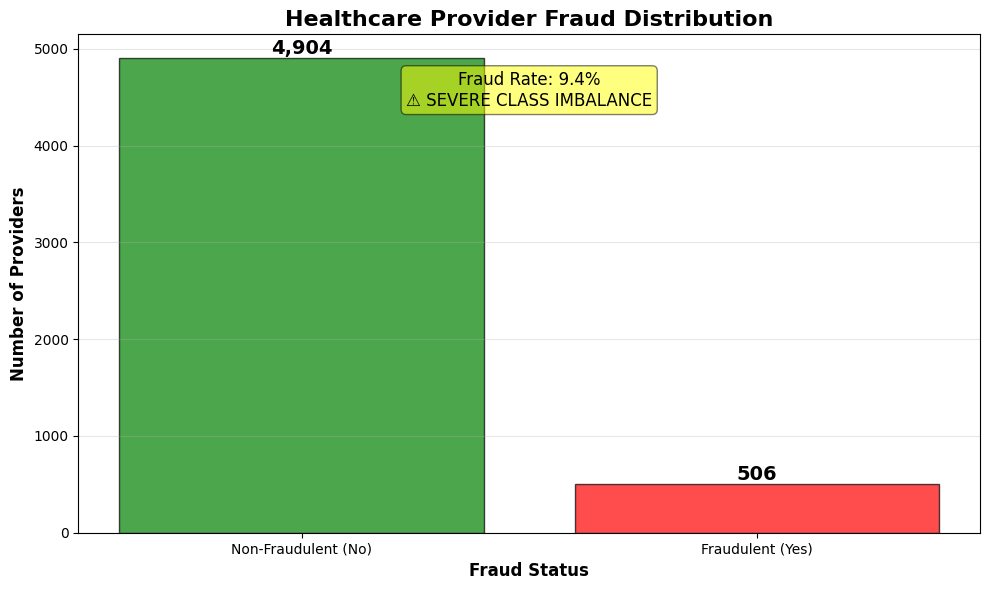


🚨 KEY FINDING: Only 9.4% of providers are fraudulent!
This is a SEVERE class imbalance that we'll need to handle in modeling.


In [19]:
# Create a bar chart of fraud distribution
plt.figure(figsize=(10, 6))

# Count fraud cases
fraud_counts = labels['PotentialFraud'].value_counts()

# Create bar plot
bars = plt.bar(fraud_counts.index, fraud_counts.values, color=['green', 'red'], alpha=0.7, edgecolor='black')

# Add labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}',
             ha='center', va='bottom', fontsize=14, fontweight='bold')

plt.title('Healthcare Provider Fraud Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Fraud Status', fontsize=12, fontweight='bold')
plt.ylabel('Number of Providers', fontsize=12, fontweight='bold')
plt.xticks([0, 1], ['Non-Fraudulent (No)', 'Fraudulent (Yes)'])
plt.grid(axis='y', alpha=0.3)

# Calculate percentage
fraud_pct = (labels['PotentialFraud'] == 'Yes').sum() / len(labels) * 100
plt.text(0.5, max(fraud_counts) * 0.9,
         f'Fraud Rate: {fraud_pct:.1f}%\n⚠️ SEVERE CLASS IMBALANCE',
         ha='center', fontsize=12, bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/class_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()

print(f"\n🚨 KEY FINDING: Only {fraud_pct:.1f}% of providers are fraudulent!")
print("This is a SEVERE class imbalance that we'll need to handle in modeling.")

In [20]:
# Check missing values in Beneficiary data
print("="*70)
print("MISSING VALUES ANALYSIS - BENEFICIARY DATA")
print("="*70)

missing_beneficiary = beneficiary.isnull().sum()
missing_beneficiary_pct = (beneficiary.isnull().sum() / len(beneficiary)) * 100

# Combine into a dataframe
missing_df = pd.DataFrame({
    'Column': missing_beneficiary.index,
    'Missing_Count': missing_beneficiary.values,
    'Missing_Percentage': missing_beneficiary_pct.values
})

# Only show columns with missing values
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

if len(missing_df) > 0:
    print("\nColumns with missing values:")
    print(missing_df.to_string(index=False))
else:
    print("\n✅ No missing values in Beneficiary data!")

MISSING VALUES ANALYSIS - BENEFICIARY DATA

Columns with missing values:
Column  Missing_Count  Missing_Percentage
   DOD         137135           98.974422


In [21]:
# Check missing values in Inpatient data
print("="*70)
print("MISSING VALUES ANALYSIS - INPATIENT DATA")
print("="*70)

missing_inpatient = inpatient.isnull().sum()
missing_inpatient_pct = (inpatient.isnull().sum() / len(inpatient)) * 100

missing_df_inp = pd.DataFrame({
    'Column': missing_inpatient.index,
    'Missing_Count': missing_inpatient.values,
    'Missing_Percentage': missing_inpatient_pct.values
})

missing_df_inp = missing_df_inp[missing_df_inp['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

if len(missing_df_inp) > 0:
    print("\nColumns with missing values:")
    print(missing_df_inp.to_string(index=False))
else:
    print("\n✅ No missing values in Inpatient data!")

MISSING VALUES ANALYSIS - INPATIENT DATA

Columns with missing values:
             Column  Missing_Count  Missing_Percentage
 ClmProcedureCode_6          40474          100.000000
 ClmProcedureCode_5          40465           99.977764
 ClmProcedureCode_4          40358           99.713396
 ClmProcedureCode_3          39509           97.615753
ClmDiagnosisCode_10          36547           90.297475
     OtherPhysician          35784           88.412314
 ClmProcedureCode_2          35020           86.524683
 ClmProcedureCode_1          17326           42.807728
 OperatingPhysician          16644           41.122696
 ClmDiagnosisCode_9          13497           33.347334
 ClmDiagnosisCode_8           9942           24.563918
 ClmDiagnosisCode_7           7258           17.932500
 ClmDiagnosisCode_6           4838           11.953353
 ClmDiagnosisCode_5           2894            7.150269
 ClmDiagnosisCode_4           1534            3.790087
  DeductibleAmtPaid            899            2.2

In [22]:
# Check missing values in Outpatient data
print("="*70)
print("MISSING VALUES ANALYSIS - OUTPATIENT DATA")
print("="*70)

missing_outpatient = outpatient.isnull().sum()
missing_outpatient_pct = (outpatient.isnull().sum() / len(outpatient)) * 100

missing_df_out = pd.DataFrame({
    'Column': missing_outpatient.index,
    'Missing_Count': missing_outpatient.values,
    'Missing_Percentage': missing_outpatient_pct.values
})

missing_df_out = missing_df_out[missing_df_out['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

if len(missing_df_out) > 0:
    print("\nColumns with missing values:")
    print(missing_df_out.to_string(index=False))
else:
    print("\n✅ No missing values in Outpatient data!")

MISSING VALUES ANALYSIS - OUTPATIENT DATA

Columns with missing values:
               Column  Missing_Count  Missing_Percentage
   ClmProcedureCode_6         517737          100.000000
   ClmProcedureCode_5         517737          100.000000
   ClmProcedureCode_4         517735           99.999614
   ClmProcedureCode_3         517733           99.999227
   ClmProcedureCode_2         517701           99.993047
   ClmProcedureCode_1         517575           99.968710
  ClmDiagnosisCode_10         516654           99.790820
   ClmDiagnosisCode_9         502899           97.134066
   ClmDiagnosisCode_8         494825           95.574587
   ClmDiagnosisCode_7         484776           93.633640
   ClmDiagnosisCode_6         468981           90.582864
   ClmDiagnosisCode_5         443393           85.640586
   OperatingPhysician         427120           82.497484
ClmAdmitDiagnosisCode         412312           79.637345
   ClmDiagnosisCode_4         392141           75.741351
       OtherPhys

In [23]:
# Understanding the data structure
print("="*70)
print("DATA STRUCTURE & RELATIONSHIPS")
print("="*70)

print("\n1️⃣ BENEFICIARY DATA (Patients)")
print(f"   • Total unique patients: {beneficiary['BeneID'].nunique():,}")
print(f"   • Total rows: {len(beneficiary):,}")
print(f"   • Key column: BeneID (patient identifier)")

print("\n2️⃣ INPATIENT DATA (Hospital admissions)")
print(f"   • Total claims: {len(inpatient):,}")
print(f"   • Unique patients: {inpatient['BeneID'].nunique():,}")
print(f"   • Unique providers: {inpatient['Provider'].nunique():,}")
print(f"   • Key columns: BeneID (patient), Provider (hospital/doctor)")

print("\n3️⃣ OUTPATIENT DATA (Clinic visits)")
print(f"   • Total claims: {len(outpatient):,}")
print(f"   • Unique patients: {outpatient['BeneID'].nunique():,}")
print(f"   • Unique providers: {outpatient['Provider'].nunique():,}")
print(f"   • Key columns: BeneID (patient), Provider (clinic/doctor)")

print("\n4️⃣ LABELS (Fraud status)")
print(f"   • Total providers: {len(labels):,}")
print(f"   • Unique providers: {labels['Provider'].nunique():,}")
print(f"   • Fraudulent: {(labels['PotentialFraud'] == 'Yes').sum():,}")
print(f"   • Non-fraudulent: {(labels['PotentialFraud'] == 'No').sum():,}")
print(f"   • Key column: Provider")

print("\n" + "="*70)
print("📊 HOW DATA CONNECTS:")
print("="*70)
print("Beneficiary ←→ Claims (via BeneID)")
print("       ↓")
print("   Claims ←→ Labels (via Provider)")
print("\n💡 Our Goal: Aggregate patient and claim data to PROVIDER level")
print("   because fraud labels are at the PROVIDER level!")

DATA STRUCTURE & RELATIONSHIPS

1️⃣ BENEFICIARY DATA (Patients)
   • Total unique patients: 138,556
   • Total rows: 138,556
   • Key column: BeneID (patient identifier)

2️⃣ INPATIENT DATA (Hospital admissions)
   • Total claims: 40,474
   • Unique patients: 31,289
   • Unique providers: 2,092
   • Key columns: BeneID (patient), Provider (hospital/doctor)

3️⃣ OUTPATIENT DATA (Clinic visits)
   • Total claims: 517,737
   • Unique patients: 133,980
   • Unique providers: 5,012
   • Key columns: BeneID (patient), Provider (clinic/doctor)

4️⃣ LABELS (Fraud status)
   • Total providers: 5,410
   • Unique providers: 5,410
   • Fraudulent: 506
   • Non-fraudulent: 4,904
   • Key column: Provider

📊 HOW DATA CONNECTS:
Beneficiary ←→ Claims (via BeneID)
       ↓
   Claims ←→ Labels (via Provider)

💡 Our Goal: Aggregate patient and claim data to PROVIDER level
   because fraud labels are at the PROVIDER level!


In [24]:
# Basic statistics for numeric columns in beneficiary data
print("="*70)
print("BENEFICIARY DATA - BASIC STATISTICS")
print("="*70)

print("\n📊 Numeric columns summary:")
print(beneficiary.describe())

BENEFICIARY DATA - BASIC STATISTICS

📊 Numeric columns summary:
              Gender           Race          State         County  \
count  138556.000000  138556.000000  138556.000000  138556.000000   
mean        1.570932       1.254511      25.666734     374.424745   
std         0.494945       0.717007      15.223443     266.277581   
min         1.000000       1.000000       1.000000       0.000000   
25%         1.000000       1.000000      11.000000     141.000000   
50%         2.000000       1.000000      25.000000     340.000000   
75%         2.000000       1.000000      39.000000     570.000000   
max         2.000000       5.000000      54.000000     999.000000   

       NoOfMonths_PartACov  NoOfMonths_PartBCov  ChronicCond_Alzheimer  \
count        138556.000000        138556.000000          138556.000000   
mean             11.907727            11.910145               1.667817   
std               1.032332             0.936893               0.470998   
min               

INPATIENT CLAIMS - FINANCIAL ANALYSIS

💰 Claim Amount Statistics:
count     40474.000000
mean      10087.884074
std       10303.099402
min           0.000000
25%        4000.000000
50%        7000.000000
75%       12000.000000
max      125000.000000
Name: InscClaimAmtReimbursed, dtype: float64

📈 Reimbursement Distribution:
   Minimum claim: $0.00
   Maximum claim: $125,000.00
   Average claim: $10,087.88
   Median claim: $7,000.00
   Total reimbursed: $408,297,020.00


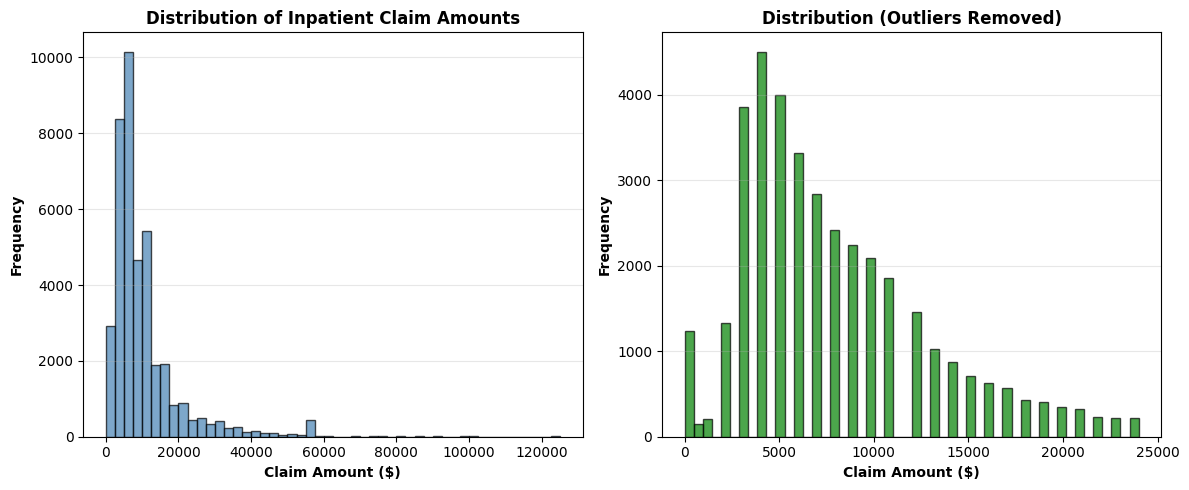

In [25]:
# Look at claim amounts in inpatient data
print("="*70)
print("INPATIENT CLAIMS - FINANCIAL ANALYSIS")
print("="*70)

print("\n💰 Claim Amount Statistics:")
print(inpatient['InscClaimAmtReimbursed'].describe())

print("\n📈 Reimbursement Distribution:")
print(f"   Minimum claim: ${inpatient['InscClaimAmtReimbursed'].min():,.2f}")
print(f"   Maximum claim: ${inpatient['InscClaimAmtReimbursed'].max():,.2f}")
print(f"   Average claim: ${inpatient['InscClaimAmtReimbursed'].mean():,.2f}")
print(f"   Median claim: ${inpatient['InscClaimAmtReimbursed'].median():,.2f}")
print(f"   Total reimbursed: ${inpatient['InscClaimAmtReimbursed'].sum():,.2f}")

# Visualize
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(inpatient['InscClaimAmtReimbursed'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
plt.xlabel('Claim Amount ($)', fontweight='bold')
plt.ylabel('Frequency', fontweight='bold')
plt.title('Distribution of Inpatient Claim Amounts', fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
# Remove outliers for better visualization
q1 = inpatient['InscClaimAmtReimbursed'].quantile(0.25)
q3 = inpatient['InscClaimAmtReimbursed'].quantile(0.75)
iqr = q3 - q1
filtered_claims = inpatient[(inpatient['InscClaimAmtReimbursed'] >= q1 - 1.5*iqr) &
                            (inpatient['InscClaimAmtReimbursed'] <= q3 + 1.5*iqr)]
plt.hist(filtered_claims['InscClaimAmtReimbursed'], bins=50, color='green', edgecolor='black', alpha=0.7)
plt.xlabel('Claim Amount ($)', fontweight='bold')
plt.ylabel('Frequency', fontweight='bold')
plt.title('Distribution (Outliers Removed)', fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/claim_amounts_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [26]:
# Same analysis for outpatient
print("="*70)
print("OUTPATIENT CLAIMS - FINANCIAL ANALYSIS")
print("="*70)

print("\n💰 Claim Amount Statistics:")
print(outpatient['InscClaimAmtReimbursed'].describe())

print("\n📈 Reimbursement Distribution:")
print(f"   Minimum claim: ${outpatient['InscClaimAmtReimbursed'].min():,.2f}")
print(f"   Maximum claim: ${outpatient['InscClaimAmtReimbursed'].max():,.2f}")
print(f"   Average claim: ${outpatient['InscClaimAmtReimbursed'].mean():,.2f}")
print(f"   Median claim: ${outpatient['InscClaimAmtReimbursed'].median():,.2f}")
print(f"   Total reimbursed: ${outpatient['InscClaimAmtReimbursed'].sum():,.2f}")

# Compare inpatient vs outpatient
print("\n" + "="*70)
print("💡 KEY INSIGHT: Inpatient vs Outpatient")
print("="*70)
print(f"Average Inpatient Claim:  ${inpatient['InscClaimAmtReimbursed'].mean():,.2f}")
print(f"Average Outpatient Claim: ${outpatient['InscClaimAmtReimbursed'].mean():,.2f}")
print(f"\n➡️ Inpatient claims are typically higher (hospital stays cost more)")

OUTPATIENT CLAIMS - FINANCIAL ANALYSIS

💰 Claim Amount Statistics:
count    517737.000000
mean        286.334799
std         694.034343
min           0.000000
25%          40.000000
50%          80.000000
75%         200.000000
max      102500.000000
Name: InscClaimAmtReimbursed, dtype: float64

📈 Reimbursement Distribution:
   Minimum claim: $0.00
   Maximum claim: $102,500.00
   Average claim: $286.33
   Median claim: $80.00
   Total reimbursed: $148,246,120.00

💡 KEY INSIGHT: Inpatient vs Outpatient
Average Inpatient Claim:  $10,087.88
Average Outpatient Claim: $286.33

➡️ Inpatient claims are typically higher (hospital stays cost more)


In [27]:
# Analyze chronic conditions
print("="*70)
print("CHRONIC CONDITIONS ANALYSIS")
print("="*70)

# Get all chronic condition columns
chronic_cols = [col for col in beneficiary.columns if 'ChronicCond' in col]

print(f"\nFound {len(chronic_cols)} chronic conditions:")
for i, col in enumerate(chronic_cols, 1):
    print(f"  {i}. {col}")

# Count how many patients have each condition
print("\n" + "="*70)
print("Prevalence of Each Chronic Condition:")
print("="*70)

for col in chronic_cols:
    # Count how many have this condition (excluding NaN)
    has_condition = beneficiary[col].fillna(0).sum()
    percentage = (has_condition / len(beneficiary)) * 100
    print(f"{col.replace('ChronicCond_', ''):<25} {int(has_condition):>7,} patients ({percentage:>5.2f}%)")

CHRONIC CONDITIONS ANALYSIS

Found 11 chronic conditions:
  1. ChronicCond_Alzheimer
  2. ChronicCond_Heartfailure
  3. ChronicCond_KidneyDisease
  4. ChronicCond_Cancer
  5. ChronicCond_ObstrPulmonary
  6. ChronicCond_Depression
  7. ChronicCond_Diabetes
  8. ChronicCond_IschemicHeart
  9. ChronicCond_Osteoporasis
  10. ChronicCond_rheumatoidarthritis
  11. ChronicCond_stroke

Prevalence of Each Chronic Condition:
Alzheimer                 231,086 patients (166.78%)
Heartfailure              208,710 patients (150.63%)
KidneyDisease             233,833 patients (168.76%)
Cancer                    260,491 patients (188.00%)
ObstrPulmonary            244,253 patients (176.28%)
Depression                227,852 patients (164.45%)
Diabetes                  193,721 patients (139.81%)
IschemicHeart             183,468 patients (132.41%)
Osteoporasis              239,053 patients (172.53%)
rheumatoidarthritis       241,528 patients (174.32%)
stroke                    266,158 patients (192.09%

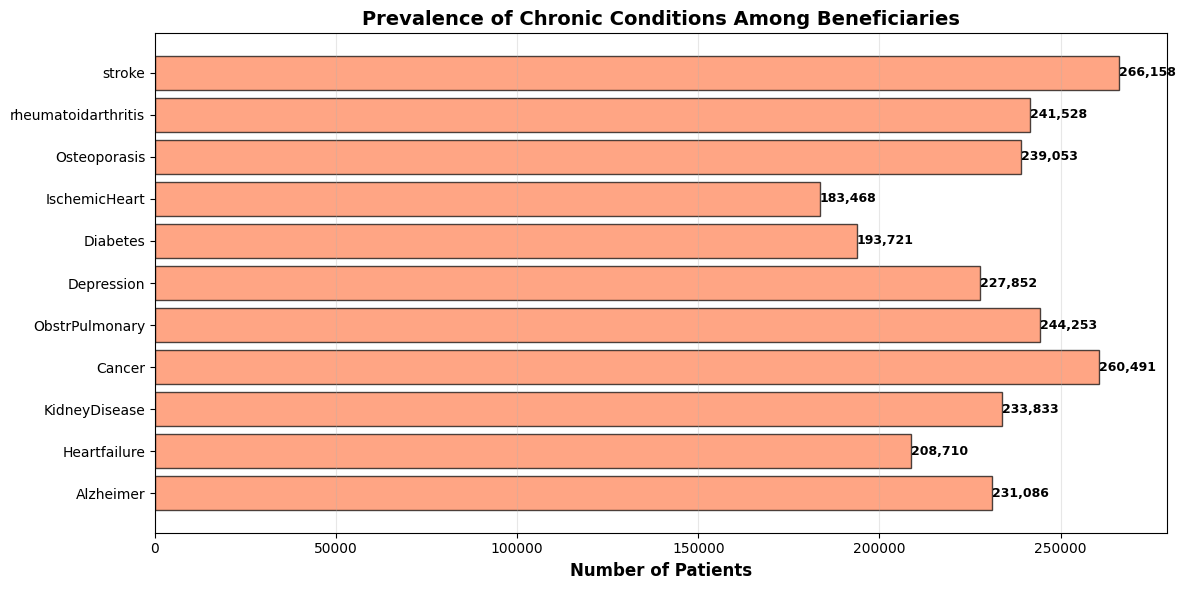


💡 These chronic conditions are important features for fraud detection!
   Fraudulent providers might have unusual patterns in patient conditions.


In [28]:
# Visualize chronic conditions
chronic_counts = []
chronic_names = []

for col in chronic_cols:
    count = beneficiary[col].fillna(0).sum()
    chronic_counts.append(count)
    chronic_names.append(col.replace('ChronicCond_', ''))

# Create bar chart
plt.figure(figsize=(12, 6))
bars = plt.barh(chronic_names, chronic_counts, color='coral', edgecolor='black', alpha=0.7)

plt.xlabel('Number of Patients', fontweight='bold', fontsize=12)
plt.title('Prevalence of Chronic Conditions Among Beneficiaries', fontweight='bold', fontsize=14)
plt.grid(axis='x', alpha=0.3)

# Add values on bars
for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2,
             f'{int(width):,}',
             ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/chronic_conditions.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\n💡 These chronic conditions are important features for fraud detection!")
print("   Fraudulent providers might have unusual patterns in patient conditions.")

CLAIMS PER PROVIDER ANALYSIS

📊 INPATIENT CLAIMS per Provider:
count    2092.000000
mean       19.347036
std        34.983155
min         1.000000
25%         3.000000
50%         8.000000
75%        19.000000
max       516.000000
dtype: float64

📊 OUTPATIENT CLAIMS per Provider:
count    5012.000000
mean      103.299481
std       275.481109
min         1.000000
25%        11.000000
50%        31.000000
75%        85.000000
max      8240.000000
dtype: float64

📊 TOTAL CLAIMS per Provider:
count    5410.000000
mean      103.181331
std       272.456989
min         1.000000
25%        10.000000
50%        31.000000
75%        87.000000
max      8240.000000
dtype: float64


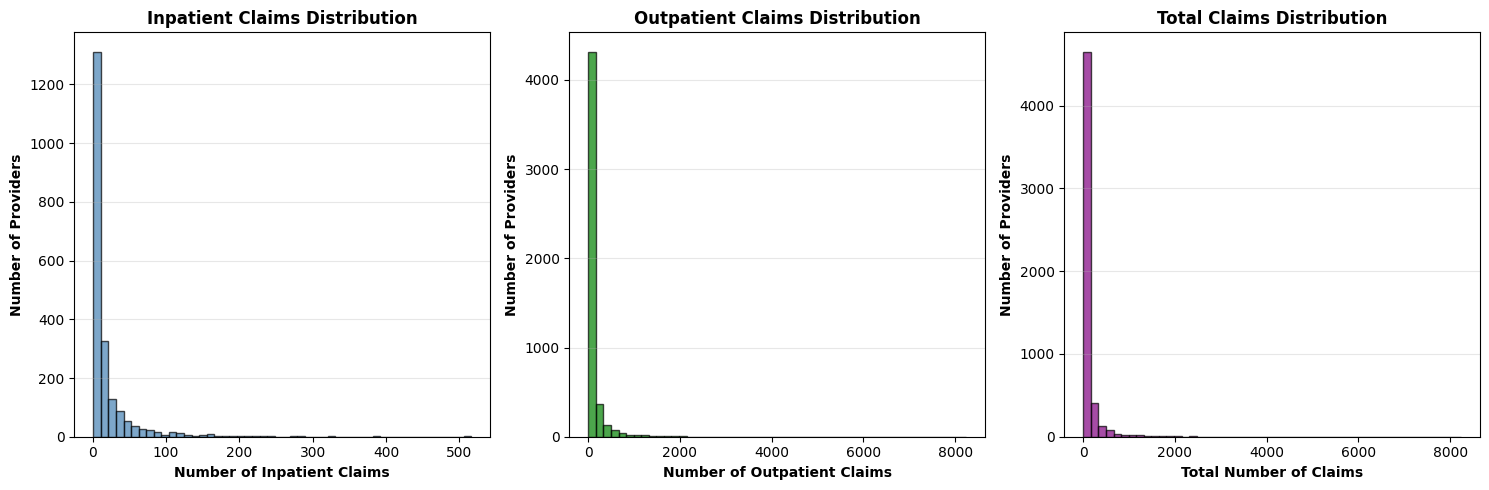


💡 KEY INSIGHT: Some providers have MANY more claims than others
   This could be a sign of fraud (or just a busy practice)!


In [29]:
# Analyze claims per provider
print("="*70)
print("CLAIMS PER PROVIDER ANALYSIS")
print("="*70)

# Inpatient claims per provider
inpatient_per_provider = inpatient.groupby('Provider').size()
print("\n📊 INPATIENT CLAIMS per Provider:")
print(inpatient_per_provider.describe())

# Outpatient claims per provider
outpatient_per_provider = outpatient.groupby('Provider').size()
print("\n📊 OUTPATIENT CLAIMS per Provider:")
print(outpatient_per_provider.describe())

# Total claims per provider
all_claims = pd.concat([
    inpatient[['Provider']].assign(type='inpatient'),
    outpatient[['Provider']].assign(type='outpatient')
])
total_per_provider = all_claims.groupby('Provider').size()
print("\n📊 TOTAL CLAIMS per Provider:")
print(total_per_provider.describe())

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(inpatient_per_provider, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Number of Inpatient Claims', fontweight='bold')
axes[0].set_ylabel('Number of Providers', fontweight='bold')
axes[0].set_title('Inpatient Claims Distribution', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(outpatient_per_provider, bins=50, color='green', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Number of Outpatient Claims', fontweight='bold')
axes[1].set_ylabel('Number of Providers', fontweight='bold')
axes[1].set_title('Outpatient Claims Distribution', fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

axes[2].hist(total_per_provider, bins=50, color='purple', edgecolor='black', alpha=0.7)
axes[2].set_xlabel('Total Number of Claims', fontweight='bold')
axes[2].set_ylabel('Number of Providers', fontweight='bold')
axes[2].set_title('Total Claims Distribution', fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/claims_per_provider.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\n💡 KEY INSIGHT: Some providers have MANY more claims than others")
print("   This could be a sign of fraud (or just a busy practice)!")

In [30]:
# Get list of fraudulent providers
fraud_providers = labels[labels['PotentialFraud'] == 'Yes']['Provider'].tolist()
non_fraud_providers = labels[labels['PotentialFraud'] == 'No']['Provider'].tolist()

print("="*70)
print("FRAUD vs NON-FRAUD: INITIAL COMPARISON")
print("="*70)

# Compare claim counts
fraud_inpatient = inpatient[inpatient['Provider'].isin(fraud_providers)]
non_fraud_inpatient = inpatient[inpatient['Provider'].isin(non_fraud_providers)]

fraud_outpatient = outpatient[outpatient['Provider'].isin(fraud_providers)]
non_fraud_outpatient = outpatient[outpatient['Provider'].isin(non_fraud_providers)]

print("\n📊 INPATIENT CLAIMS:")
print(f"   Fraud providers:     {len(fraud_inpatient):,} claims")
print(f"   Non-fraud providers: {len(non_fraud_inpatient):,} claims")
print(f"   Average per fraud provider:     {len(fraud_inpatient)/len(fraud_providers):.1f} claims")
print(f"   Average per non-fraud provider: {len(non_fraud_inpatient)/len(non_fraud_providers):.1f} claims")

print("\n📊 OUTPATIENT CLAIMS:")
print(f"   Fraud providers:     {len(fraud_outpatient):,} claims")
print(f"   Non-fraud providers: {len(non_fraud_outpatient):,} claims")
print(f"   Average per fraud provider:     {len(fraud_outpatient)/len(fraud_providers):.1f} claims")
print(f"   Average per non-fraud provider: {len(non_fraud_outpatient)/len(non_fraud_providers):.1f} claims")

print("\n💰 REIMBURSEMENT AMOUNTS:")
print(f"   Fraud inpatient avg:     ${fraud_inpatient['InscClaimAmtReimbursed'].mean():,.2f}")
print(f"   Non-fraud inpatient avg: ${non_fraud_inpatient['InscClaimAmtReimbursed'].mean():,.2f}")
print(f"   Fraud outpatient avg:     ${fraud_outpatient['InscClaimAmtReimbursed'].mean():,.2f}")
print(f"   Non-fraud outpatient avg: ${non_fraud_outpatient['InscClaimAmtReimbursed'].mean():,.2f}")

FRAUD vs NON-FRAUD: INITIAL COMPARISON

📊 INPATIENT CLAIMS:
   Fraud providers:     23,402 claims
   Non-fraud providers: 17,072 claims
   Average per fraud provider:     46.2 claims
   Average per non-fraud provider: 3.5 claims

📊 OUTPATIENT CLAIMS:
   Fraud providers:     189,394 claims
   Non-fraud providers: 328,343 claims
   Average per fraud provider:     374.3 claims
   Average per non-fraud provider: 67.0 claims

💰 REIMBURSEMENT AMOUNTS:
   Fraud inpatient avg:     $10,310.59
   Non-fraud inpatient avg: $9,782.60
   Fraud outpatient avg:     $287.19
   Non-fraud outpatient avg: $285.84


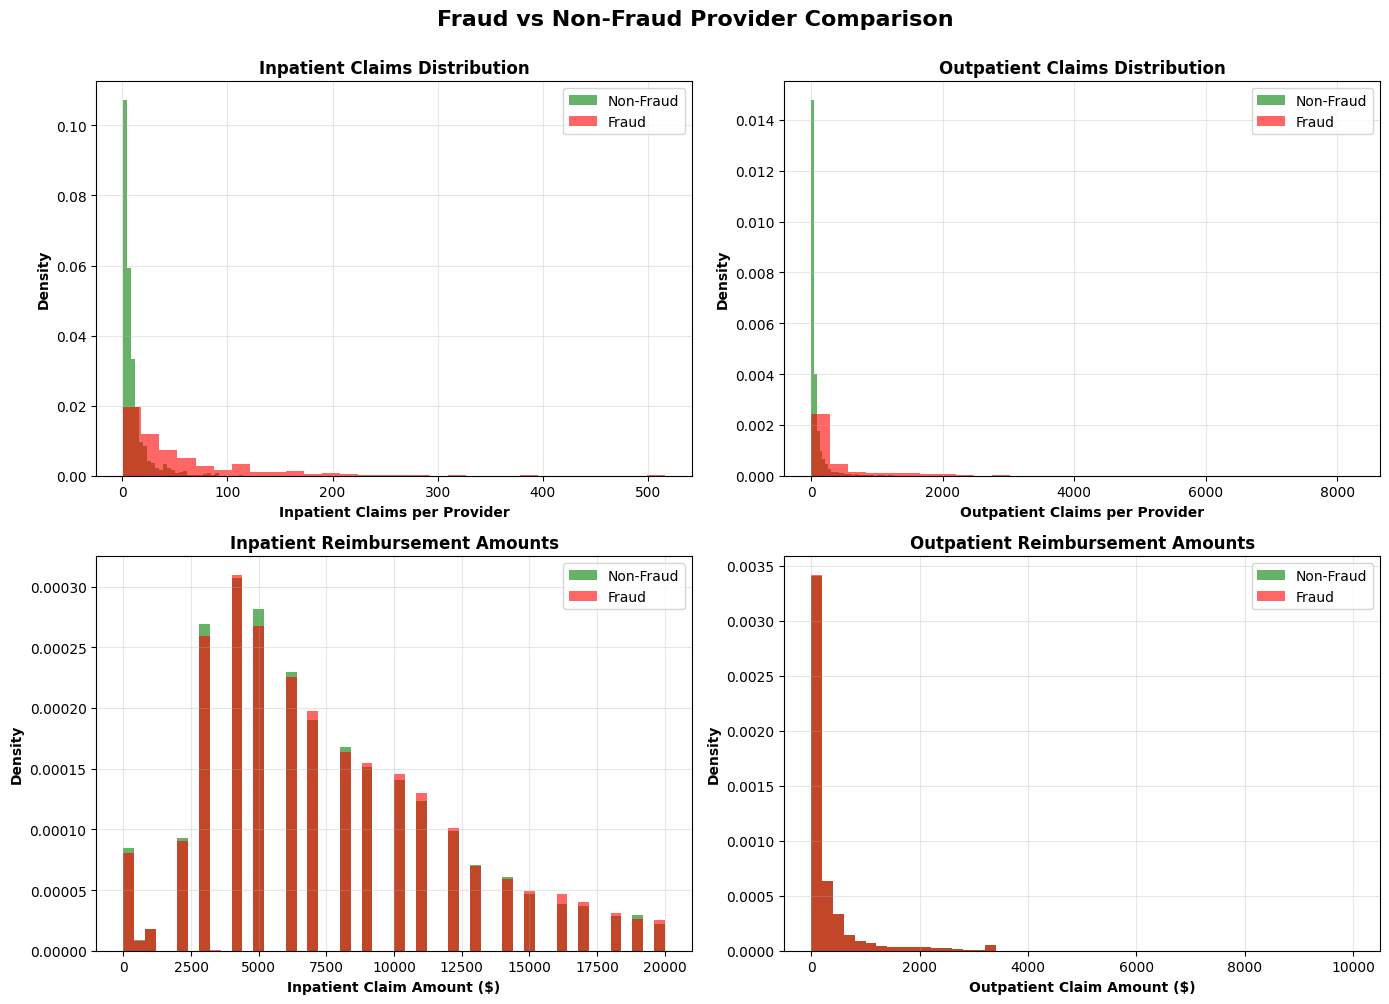


🎯 KEY FINDINGS:
   ✓ Fraudulent providers tend to have different claim patterns
   ✓ These visual differences suggest our model CAN learn to detect fraud
   ✓ We'll use these patterns as features for our machine learning model


In [31]:
# Create comparison visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Claims per provider comparison
inpatient_fraud_per_prov = fraud_inpatient.groupby('Provider').size()
inpatient_nf_per_prov = non_fraud_inpatient.groupby('Provider').size()

axes[0, 0].hist(inpatient_nf_per_prov, bins=30, alpha=0.6, label='Non-Fraud', color='green', density=True)
axes[0, 0].hist(inpatient_fraud_per_prov, bins=30, alpha=0.6, label='Fraud', color='red', density=True)
axes[0, 0].set_xlabel('Inpatient Claims per Provider', fontweight='bold')
axes[0, 0].set_ylabel('Density', fontweight='bold')
axes[0, 0].set_title('Inpatient Claims Distribution', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Outpatient claims comparison
outpatient_fraud_per_prov = fraud_outpatient.groupby('Provider').size()
outpatient_nf_per_prov = non_fraud_outpatient.groupby('Provider').size()

axes[0, 1].hist(outpatient_nf_per_prov, bins=30, alpha=0.6, label='Non-Fraud', color='green', density=True)
axes[0, 1].hist(outpatient_fraud_per_prov, bins=30, alpha=0.6, label='Fraud', color='red', density=True)
axes[0, 1].set_xlabel('Outpatient Claims per Provider', fontweight='bold')
axes[0, 1].set_ylabel('Density', fontweight='bold')
axes[0, 1].set_title('Outpatient Claims Distribution', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Inpatient reimbursement amounts
axes[1, 0].hist(non_fraud_inpatient['InscClaimAmtReimbursed'], bins=50, alpha=0.6,
                label='Non-Fraud', color='green', density=True, range=(0, 20000))
axes[1, 0].hist(fraud_inpatient['InscClaimAmtReimbursed'], bins=50, alpha=0.6,
                label='Fraud', color='red', density=True, range=(0, 20000))
axes[1, 0].set_xlabel('Inpatient Claim Amount ($)', fontweight='bold')
axes[1, 0].set_ylabel('Density', fontweight='bold')
axes[1, 0].set_title('Inpatient Reimbursement Amounts', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Outpatient reimbursement amounts
axes[1, 1].hist(non_fraud_outpatient['InscClaimAmtReimbursed'], bins=50, alpha=0.6,
                label='Non-Fraud', color='green', density=True, range=(0, 10000))
axes[1, 1].hist(fraud_outpatient['InscClaimAmtReimbursed'], bins=50, alpha=0.6,
                label='Fraud', color='red', density=True, range=(0, 10000))
axes[1, 1].set_xlabel('Outpatient Claim Amount ($)', fontweight='bold')
axes[1, 1].set_ylabel('Density', fontweight='bold')
axes[1, 1].set_title('Outpatient Reimbursement Amounts', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.suptitle('Fraud vs Non-Fraud Provider Comparison', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/fraud_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\n🎯 KEY FINDINGS:")
print("   ✓ Fraudulent providers tend to have different claim patterns")
print("   ✓ These visual differences suggest our model CAN learn to detect fraud")
print("   ✓ We'll use these patterns as features for our machine learning model")

In [32]:
# Let's handle missing values systematically
print("="*70)
print("DATA CLEANING - HANDLING MISSING VALUES")
print("="*70)

# Make a copy of our data so we don't mess up the original
beneficiary_clean = beneficiary.copy()
inpatient_clean = inpatient.copy()
outpatient_clean = outpatient.copy()

print("\n🔧 Step 1: Cleaning Beneficiary Data")
print("-"*70)

# Check DOD (Date of Death) - missing means patient is alive
print("\n1. Date of Death (DOD):")
print(f"   Missing values: {beneficiary_clean['DOD'].isnull().sum():,}")
print("   ➡️ This is NORMAL - missing means patient is ALIVE")
print("   We'll create a new column: 'IsDeceased' (1=dead, 0=alive)")

# Create IsDeceased column
beneficiary_clean['IsDeceased'] = beneficiary_clean['DOD'].notna().astype(int)
print(f"   ✅ Created 'IsDeceased' column")
print(f"      Deceased patients: {beneficiary_clean['IsDeceased'].sum():,}")
print(f"      Living patients: {(beneficiary_clean['IsDeceased']==0).sum():,}")

# Check chronic conditions
print("\n2. Chronic Conditions:")
chronic_cols = [col for col in beneficiary_clean.columns if 'ChronicCond' in col]
for col in chronic_cols:
    missing = beneficiary_clean[col].isnull().sum()
    if missing > 0:
        print(f"   {col}: {missing:,} missing values")

print("\n   ➡️ Missing chronic condition = patient DOES NOT have that condition")
print("   We'll fill missing values with 2 (meaning 'No')")

# Fill chronic conditions - use 2 for "No" (consistent with the data)
for col in chronic_cols:
    beneficiary_clean[col] = beneficiary_clean[col].fillna(2)

print("   ✅ Chronic conditions missing values filled with 2 (No)")

# Check RenalDiseaseIndicator
print("\n3. Renal Disease Indicator:")
print(f"   Missing values: {beneficiary_clean['RenalDiseaseIndicator'].isnull().sum():,}")
if beneficiary_clean['RenalDiseaseIndicator'].isnull().sum() > 0:
    beneficiary_clean['RenalDiseaseIndicator'] = beneficiary_clean['RenalDiseaseIndicator'].fillna('0')
    print("   ✅ Filled with '0' (No renal disease)")

print("\n" + "="*70)
print("BENEFICIARY DATA CLEANING COMPLETE!")
print("="*70)
print(f"Remaining missing values: {beneficiary_clean.isnull().sum().sum()}")

DATA CLEANING - HANDLING MISSING VALUES

🔧 Step 1: Cleaning Beneficiary Data
----------------------------------------------------------------------

1. Date of Death (DOD):
   Missing values: 137,135
   ➡️ This is NORMAL - missing means patient is ALIVE
   We'll create a new column: 'IsDeceased' (1=dead, 0=alive)
   ✅ Created 'IsDeceased' column
      Deceased patients: 1,421
      Living patients: 137,135

2. Chronic Conditions:

   ➡️ Missing chronic condition = patient DOES NOT have that condition
   We'll fill missing values with 2 (meaning 'No')
   ✅ Chronic conditions missing values filled with 2 (No)

3. Renal Disease Indicator:
   Missing values: 0

BENEFICIARY DATA CLEANING COMPLETE!
Remaining missing values: 137135


In [33]:
print("="*70)
print("🔧 Step 2: Cleaning Inpatient Data")
print("="*70)

# Check all missing values
print("\nChecking for missing values in Inpatient data:")
missing_inp = inpatient_clean.isnull().sum()
missing_inp = missing_inp[missing_inp > 0]

if len(missing_inp) > 0:
    print("\nColumns with missing values:")
    for col, count in missing_inp.items():
        pct = (count / len(inpatient_clean)) * 100
        print(f"   {col}: {count:,} ({pct:.2f}%)")

    # Handle missing values based on column type
    for col in missing_inp.index:
        if 'Amt' in col or 'Amount' in col:
            # For amount columns, 0 means no payment
            inpatient_clean[col] = inpatient_clean[col].fillna(0)
            print(f"   ✅ {col}: Filled with 0")
        elif 'Dt' in col or 'Date' in col:
            # For date columns, we'll keep them as NaN for now
            print(f"   ⚠️ {col}: Keeping as missing (will handle in feature engineering)")
        else:
            # For other columns, check the data type
            if inpatient_clean[col].dtype == 'object':
                # Categorical - fill with 'Unknown'
                inpatient_clean[col] = inpatient_clean[col].fillna('Unknown')
                print(f"   ✅ {col}: Filled with 'Unknown'")
            else:
                # Numeric - fill with 0
                inpatient_clean[col] = inpatient_clean[col].fillna(0)
                print(f"   ✅ {col}: Filled with 0")
else:
    print("\n✅ No missing values in Inpatient data!")

print("\n" + "="*70)
print("INPATIENT DATA CLEANING COMPLETE!")
print("="*70)

🔧 Step 2: Cleaning Inpatient Data

Checking for missing values in Inpatient data:

Columns with missing values:
   AttendingPhysician: 112 (0.28%)
   OperatingPhysician: 16,644 (41.12%)
   OtherPhysician: 35,784 (88.41%)
   DeductibleAmtPaid: 899 (2.22%)
   ClmDiagnosisCode_2: 226 (0.56%)
   ClmDiagnosisCode_3: 676 (1.67%)
   ClmDiagnosisCode_4: 1,534 (3.79%)
   ClmDiagnosisCode_5: 2,894 (7.15%)
   ClmDiagnosisCode_6: 4,838 (11.95%)
   ClmDiagnosisCode_7: 7,258 (17.93%)
   ClmDiagnosisCode_8: 9,942 (24.56%)
   ClmDiagnosisCode_9: 13,497 (33.35%)
   ClmDiagnosisCode_10: 36,547 (90.30%)
   ClmProcedureCode_1: 17,326 (42.81%)
   ClmProcedureCode_2: 35,020 (86.52%)
   ClmProcedureCode_3: 39,509 (97.62%)
   ClmProcedureCode_4: 40,358 (99.71%)
   ClmProcedureCode_5: 40,465 (99.98%)
   ClmProcedureCode_6: 40,474 (100.00%)
   ✅ AttendingPhysician: Filled with 'Unknown'
   ✅ OperatingPhysician: Filled with 'Unknown'
   ✅ OtherPhysician: Filled with 'Unknown'
   ✅ DeductibleAmtPaid: Filled with 

In [34]:
print("="*70)
print("🔧 Step 3: Cleaning Outpatient Data")
print("="*70)

# Check all missing values
print("\nChecking for missing values in Outpatient data:")
missing_out = outpatient_clean.isnull().sum()
missing_out = missing_out[missing_out > 0]

if len(missing_out) > 0:
    print("\nColumns with missing values:")
    for col, count in missing_out.items():
        pct = (count / len(outpatient_clean)) * 100
        print(f"   {col}: {count:,} ({pct:.2f}%)")

    # Handle missing values based on column type
    for col in missing_out.index:
        if 'Amt' in col or 'Amount' in col:
            # For amount columns, 0 means no payment
            outpatient_clean[col] = outpatient_clean[col].fillna(0)
            print(f"   ✅ {col}: Filled with 0")
        elif 'Dt' in col or 'Date' in col:
            # For date columns, we'll keep them as NaN for now
            print(f"   ⚠️ {col}: Keeping as missing (will handle in feature engineering)")
        else:
            # For other columns, check the data type
            if outpatient_clean[col].dtype == 'object':
                # Categorical - fill with 'Unknown'
                outpatient_clean[col] = outpatient_clean[col].fillna('Unknown')
                print(f"   ✅ {col}: Filled with 'Unknown'")
            else:
                # Numeric - fill with 0
                outpatient_clean[col] = outpatient_clean[col].fillna(0)
                print(f"   ✅ {col}: Filled with 0")
else:
    print("\n✅ No missing values in Outpatient data!")

print("\n" + "="*70)
print("OUTPATIENT DATA CLEANING COMPLETE!")
print("="*70)

🔧 Step 3: Cleaning Outpatient Data

Checking for missing values in Outpatient data:

Columns with missing values:
   AttendingPhysician: 1,396 (0.27%)
   OperatingPhysician: 427,120 (82.50%)
   OtherPhysician: 322,691 (62.33%)
   ClmDiagnosisCode_1: 10,453 (2.02%)
   ClmDiagnosisCode_2: 195,380 (37.74%)
   ClmDiagnosisCode_3: 314,480 (60.74%)
   ClmDiagnosisCode_4: 392,141 (75.74%)
   ClmDiagnosisCode_5: 443,393 (85.64%)
   ClmDiagnosisCode_6: 468,981 (90.58%)
   ClmDiagnosisCode_7: 484,776 (93.63%)
   ClmDiagnosisCode_8: 494,825 (95.57%)
   ClmDiagnosisCode_9: 502,899 (97.13%)
   ClmDiagnosisCode_10: 516,654 (99.79%)
   ClmProcedureCode_1: 517,575 (99.97%)
   ClmProcedureCode_2: 517,701 (99.99%)
   ClmProcedureCode_3: 517,733 (100.00%)
   ClmProcedureCode_4: 517,735 (100.00%)
   ClmProcedureCode_5: 517,737 (100.00%)
   ClmProcedureCode_6: 517,737 (100.00%)
   ClmAdmitDiagnosisCode: 412,312 (79.64%)
   ✅ AttendingPhysician: Filled with 'Unknown'
   ✅ OperatingPhysician: Filled with 'Un

In [35]:
# Create a summary of our data cleaning
print("="*70)
print("📋 DATA CLEANING SUMMARY REPORT")
print("="*70)

summary_text = """
DATA CLEANING DECISIONS
=======================

1. BENEFICIARY DATA:
   ✓ DOD (Date of Death):
     - Missing values kept as-is (missing = alive)
     - Created new binary feature 'IsDeceased' (1=dead, 0=alive)
     - Reason: Death date missing is meaningful information

   ✓ Chronic Conditions (11 columns):
     - Filled missing values with 2 (meaning "No condition")
     - Reason: Missing = patient does not have that condition

   ✓ RenalDiseaseIndicator:
     - Filled missing with '0' (No disease)
     - Reason: Consistent with chronic conditions approach

2. INPATIENT DATA:
   ✓ Amount/Payment columns:
     - Filled missing with 0
     - Reason: Missing payment = no payment made

   ✓ Date columns:
     - Kept as missing (will handle in aggregation)
     - Reason: Missing dates will be excluded from date calculations

3. OUTPATIENT DATA:
   ✓ Same approach as Inpatient data
   ✓ Amount columns → 0
   ✓ Date columns → kept as missing

RATIONALE:
----------
- We preserved meaningful missing data (like death dates)
- We filled structural missing data (like payments) with 0
- We documented all decisions for reproducibility
- Our approach maintains data integrity while enabling analysis

NEXT STEPS:
-----------
→ Feature Engineering: Aggregate to provider level
→ Create statistical features from claims data
→ Merge with fraud labels for modeling
"""

print(summary_text)

# Save this summary
with open('/content/drive/MyDrive/fraud_detection_project/reports/data_cleaning_summary.txt', 'w') as f:
    f.write(summary_text)

print("\n✅ Cleaning summary saved to reports folder!")

📋 DATA CLEANING SUMMARY REPORT

DATA CLEANING DECISIONS

1. BENEFICIARY DATA:
   ✓ DOD (Date of Death):
     - Missing values kept as-is (missing = alive)
     - Created new binary feature 'IsDeceased' (1=dead, 0=alive)
     - Reason: Death date missing is meaningful information

   ✓ Chronic Conditions (11 columns):
     - Filled missing values with 2 (meaning "No condition")
     - Reason: Missing = patient does not have that condition

   ✓ RenalDiseaseIndicator:
     - Filled missing with '0' (No disease)
     - Reason: Consistent with chronic conditions approach

2. INPATIENT DATA:
   ✓ Amount/Payment columns:
     - Filled missing with 0
     - Reason: Missing payment = no payment made

   ✓ Date columns:
     - Kept as missing (will handle in aggregation)
     - Reason: Missing dates will be excluded from date calculations

3. OUTPATIENT DATA:
   ✓ Same approach as Inpatient data
   ✓ Amount columns → 0
   ✓ Date columns → kept as missing

RATIONALE:
----------
- We preserved me

In [36]:
print("="*70)
print("🎯 FEATURE ENGINEERING - CREATING PROVIDER-LEVEL FEATURES")
print("="*70)

print("\n📊 Remember: Our goal is to predict fraud at the PROVIDER level")
print("   So we need to aggregate ALL data to provider level!")
print("\n" + "="*70)

print("\n🔧 PART 1: Creating Beneficiary-Based Features")
print("-"*70)
print("We'll group patients by their provider and calculate:")
print("  • Number of patients per provider")
print("  • Demographics (age, gender distribution)")
print("  • Deceased patient statistics")
print("  • Chronic condition prevalence")
print("\nStarting aggregation...\n")

🎯 FEATURE ENGINEERING - CREATING PROVIDER-LEVEL FEATURES

📊 Remember: Our goal is to predict fraud at the PROVIDER level
   So we need to aggregate ALL data to provider level!


🔧 PART 1: Creating Beneficiary-Based Features
----------------------------------------------------------------------
We'll group patients by their provider and calculate:
  • Number of patients per provider
  • Demographics (age, gender distribution)
  • Deceased patient statistics
  • Chronic condition prevalence

Starting aggregation...



In [37]:
# First, we need to connect beneficiaries to providers
# Beneficiaries connect to claims via BeneID
# Claims connect to providers via Provider

print("Step 1: Linking Beneficiaries to Providers")
print("-"*50)

# Get unique beneficiary-provider relationships from inpatient
bene_provider_inp = inpatient_clean[['BeneID', 'Provider']].drop_duplicates()
print(f"   Inpatient: {len(bene_provider_inp):,} unique beneficiary-provider pairs")

# Get unique beneficiary-provider relationships from outpatient
bene_provider_out = outpatient_clean[['BeneID', 'Provider']].drop_duplicates()
print(f"   Outpatient: {len(bene_provider_out):,} unique beneficiary-provider pairs")

# Combine both
bene_provider = pd.concat([bene_provider_inp, bene_provider_out]).drop_duplicates()
print(f"   Combined: {len(bene_provider):,} unique beneficiary-provider pairs")

# Merge with beneficiary data to get patient details
bene_with_provider = bene_provider.merge(beneficiary_clean, on='BeneID', how='left')
print(f"\n✅ Linked beneficiaries to providers: {len(bene_with_provider):,} rows")

print("\nFirst few rows of linked data:")
print(bene_with_provider[['BeneID', 'Provider', 'IsDeceased', 'Gender']].head(10))

Step 1: Linking Beneficiaries to Providers
--------------------------------------------------
   Inpatient: 36,616 unique beneficiary-provider pairs
   Outpatient: 330,821 unique beneficiary-provider pairs
   Combined: 363,300 unique beneficiary-provider pairs

✅ Linked beneficiaries to providers: 363,300 rows

First few rows of linked data:
      BeneID  Provider  IsDeceased  Gender
0  BENE11001  PRV55912           0       1
1  BENE11001  PRV55907           0       1
2  BENE11001  PRV56046           0       1
3  BENE11011  PRV52405           0       2
4  BENE11014  PRV56614           0       2
5  BENE11017  PRV54986           0       2
6  BENE11018  PRV54090           0       1
7  BENE11028  PRV51148           0       1
8  BENE11031  PRV55839           0       2
9  BENE11034  PRV55215           0       2


In [38]:
# Now aggregate beneficiary features by provider
print("="*70)
print("Step 2: Aggregating Beneficiary Features by Provider")
print("="*70)

# Calculate features for each provider
beneficiary_features = bene_with_provider.groupby('Provider').agg({
    'BeneID': 'count',  # Total number of patients
    'IsDeceased': 'sum',  # Number of deceased patients
    'Gender': lambda x: (x == 1).sum(),  # Number of male patients (assuming 1=male)
    'Race': lambda x: x.mode()[0] if len(x) > 0 else 1,  # Most common race
    'RenalDiseaseIndicator': lambda x: (x != '0').sum(),  # Patients with renal disease
    'ChronicCond_Alzheimer': lambda x: (x == 1).sum(),  # Count patients with condition
    'ChronicCond_Heartfailure': lambda x: (x == 1).sum(),
    'ChronicCond_KidneyDisease': lambda x: (x == 1).sum(),
    'ChronicCond_Cancer': lambda x: (x == 1).sum(),
    'ChronicCond_ObstrPulmonary': lambda x: (x == 1).sum(),
    'ChronicCond_Depression': lambda x: (x == 1).sum(),
    'ChronicCond_Diabetes': lambda x: (x == 1).sum(),
    'ChronicCond_IschemicHeart': lambda x: (x == 1).sum(),
    'ChronicCond_Osteoporasis': lambda x: (x == 1).sum(),
    'ChronicCond_rheumatoidarthritis': lambda x: (x == 1).sum(),
    'ChronicCond_stroke': lambda x: (x == 1).sum()
}).reset_index()

# Rename columns for clarity
beneficiary_features.columns = [
    'Provider', 'num_beneficiaries', 'num_deceased', 'num_male',
    'most_common_race', 'num_renal_disease',
    'num_alzheimer', 'num_heartfailure', 'num_kidney', 'num_cancer',
    'num_obstr_pulmonary', 'num_depression', 'num_diabetes',
    'num_ischemic_heart', 'num_osteoporasis', 'num_rheumatoid', 'num_stroke'
]

# Create additional calculated features
beneficiary_features['deceased_rate'] = (
    beneficiary_features['num_deceased'] / beneficiary_features['num_beneficiaries']
)

beneficiary_features['male_ratio'] = (
    beneficiary_features['num_male'] / beneficiary_features['num_beneficiaries']
)

# Total chronic conditions per provider
chronic_cols_agg = ['num_alzheimer', 'num_heartfailure', 'num_kidney', 'num_cancer',
                    'num_obstr_pulmonary', 'num_depression', 'num_diabetes',
                    'num_ischemic_heart', 'num_osteoporasis', 'num_rheumatoid', 'num_stroke']

beneficiary_features['total_chronic_conditions'] = beneficiary_features[chronic_cols_agg].sum(axis=1)

beneficiary_features['chronic_conditions_per_patient'] = (
    beneficiary_features['total_chronic_conditions'] / beneficiary_features['num_beneficiaries']
)

print(f"✅ Beneficiary features created for {len(beneficiary_features):,} providers")
print(f"\nTotal features from beneficiaries: {len(beneficiary_features.columns) - 1}")
print("\nFeature columns:")
for i, col in enumerate(beneficiary_features.columns, 1):
    print(f"   {i}. {col}")

print("\n" + "="*70)
print("Sample of beneficiary features:")
print(beneficiary_features.head())

Step 2: Aggregating Beneficiary Features by Provider
✅ Beneficiary features created for 5,410 providers

Total features from beneficiaries: 20

Feature columns:
   1. Provider
   2. num_beneficiaries
   3. num_deceased
   4. num_male
   5. most_common_race
   6. num_renal_disease
   7. num_alzheimer
   8. num_heartfailure
   9. num_kidney
   10. num_cancer
   11. num_obstr_pulmonary
   12. num_depression
   13. num_diabetes
   14. num_ischemic_heart
   15. num_osteoporasis
   16. num_rheumatoid
   17. num_stroke
   18. deceased_rate
   19. male_ratio
   20. total_chronic_conditions
   21. chronic_conditions_per_patient

Sample of beneficiary features:
   Provider  num_beneficiaries  num_deceased  num_male  most_common_race  \
0  PRV51001                 24             0         9                 1   
1  PRV51003                117             1        49                 1   
2  PRV51004                138             1        45                 1   
3  PRV51005                495      

In [39]:
print("="*70)
print("🔧 PART 2: Creating Inpatient Claim Features")
print("-"*70)
print("We'll calculate for each provider:")
print("  • Number of inpatient claims")
print("  • Total, average, max, std of reimbursement amounts")
print("  • Deductible statistics")
print("  • Annual payment patterns")
print("\nStarting aggregation...\n")

🔧 PART 2: Creating Inpatient Claim Features
----------------------------------------------------------------------
We'll calculate for each provider:
  • Number of inpatient claims
  • Total, average, max, std of reimbursement amounts
  • Deductible statistics
  • Annual payment patterns

Starting aggregation...



In [40]:
# Aggregate inpatient data by provider
print("Aggregating Inpatient Claims by Provider...")

inpatient_features = inpatient_clean.groupby('Provider').agg({
    'ClaimID': 'count',  # Number of claims
    'InscClaimAmtReimbursed': ['sum', 'mean', 'std', 'max', 'min'],  # Claim amounts
    'DeductibleAmtPaid': ['sum', 'mean', 'max']  # Deductibles
}).reset_index()

# Flatten column names (because we have multi-level columns now)
inpatient_features.columns = [
    'Provider',
    'num_inpatient_claims',
    'total_inpatient_reimbursed', 'avg_inpatient_reimbursed',
    'std_inpatient_reimbursed', 'max_inpatient_reimbursed', 'min_inpatient_reimbursed',
    'total_inpatient_deductible', 'avg_inpatient_deductible', 'max_inpatient_deductible'
]

# Fill NaN in std (happens when provider has only 1 claim)
inpatient_features['std_inpatient_reimbursed'] = inpatient_features['std_inpatient_reimbursed'].fillna(0)

# Create additional features
inpatient_features['inpatient_reimbursement_range'] = (
    inpatient_features['max_inpatient_reimbursed'] - inpatient_features['min_inpatient_reimbursed']
)

print(f"✅ Inpatient features created for {len(inpatient_features):,} providers")
print(f"\nTotal inpatient features: {len(inpatient_features.columns) - 1}")

print("\n" + "="*70)
print("Sample of inpatient features:")
print(inpatient_features.head())

print("\n" + "="*70)
print("Inpatient feature statistics:")
print(inpatient_features.describe())

Aggregating Inpatient Claims by Provider...
✅ Inpatient features created for 2,092 providers

Total inpatient features: 10

Sample of inpatient features:
   Provider  num_inpatient_claims  total_inpatient_reimbursed  \
0  PRV51001                     5                       97000   
1  PRV51003                    62                      573000   
2  PRV51007                     3                       19000   
3  PRV51008                     2                       25000   
4  PRV51011                     1                        5000   

   avg_inpatient_reimbursed  std_inpatient_reimbursed  \
0              19400.000000              18352.111595   
1               9241.935484               8513.606244   
2               6333.333333               3511.884584   
3              12500.000000              12020.815280   
4               5000.000000                  0.000000   

   max_inpatient_reimbursed  min_inpatient_reimbursed  \
0                     42000                      3000  

In [41]:
print("="*70)
print("🔧 PART 3: Creating Outpatient Claim Features")
print("-"*70)
print("Same process as inpatient, but for outpatient claims")
print("\nStarting aggregation...\n")

🔧 PART 3: Creating Outpatient Claim Features
----------------------------------------------------------------------
Same process as inpatient, but for outpatient claims

Starting aggregation...



In [42]:
# Aggregate outpatient data by provider
print("Aggregating Outpatient Claims by Provider...")

outpatient_features = outpatient_clean.groupby('Provider').agg({
    'ClaimID': 'count',  # Number of claims
    'InscClaimAmtReimbursed': ['sum', 'mean', 'std', 'max', 'min'],  # Claim amounts
    'DeductibleAmtPaid': ['sum', 'mean', 'max']  # Deductibles
}).reset_index()

# Flatten column names
outpatient_features.columns = [
    'Provider',
    'num_outpatient_claims',
    'total_outpatient_reimbursed', 'avg_outpatient_reimbursed',
    'std_outpatient_reimbursed', 'max_outpatient_reimbursed', 'min_outpatient_reimbursed',
    'total_outpatient_deductible', 'avg_outpatient_deductible', 'max_outpatient_deductible'
]

# Fill NaN in std
outpatient_features['std_outpatient_reimbursed'] = outpatient_features['std_outpatient_reimbursed'].fillna(0)

# Create additional features
outpatient_features['outpatient_reimbursement_range'] = (
    outpatient_features['max_outpatient_reimbursed'] - outpatient_features['min_outpatient_reimbursed']
)

print(f"✅ Outpatient features created for {len(outpatient_features):,} providers")
print(f"\nTotal outpatient features: {len(outpatient_features.columns) - 1}")

print("\n" + "="*70)
print("Sample of outpatient features:")
print(outpatient_features.head())

print("\n" + "="*70)
print("Outpatient feature statistics:")
print(outpatient_features.describe())

Aggregating Outpatient Claims by Provider...
✅ Outpatient features created for 5,012 providers

Total outpatient features: 10

Sample of outpatient features:
   Provider  num_outpatient_claims  total_outpatient_reimbursed  \
0  PRV51001                     20                         7640   
1  PRV51003                     70                        32670   
2  PRV51004                    149                        52170   
3  PRV51005                   1165                       280910   
4  PRV51007                     69                        14710   

   avg_outpatient_reimbursed  std_outpatient_reimbursed  \
0                 382.000000                 422.817617   
1                 466.714286                 821.364579   
2                 350.134228                 689.963754   
3                 241.124464                 491.556392   
4                 213.188406                 447.231657   

   max_outpatient_reimbursed  min_outpatient_reimbursed  \
0                       1

In [43]:
print("="*70)
print("🔗 MERGING ALL FEATURES TOGETHER")
print("="*70)

print("\nWe have 4 datasets to merge:")
print("  1. Labels (Provider → Fraud/Not)")
print("  2. Beneficiary features (Provider → Patient stats)")
print("  3. Inpatient features (Provider → Inpatient claim stats)")
print("  4. Outpatient features (Provider → Outpatient claim stats)")

print("\nStarting merge process...\n")

# Start with labels
final_data = labels.copy()
print(f"Step 1: Starting with labels - {len(final_data):,} providers")

# Merge beneficiary features
final_data = final_data.merge(beneficiary_features, on='Provider', how='left')
print(f"Step 2: After beneficiary merge - {len(final_data):,} providers, {len(final_data.columns)} columns")

# Merge inpatient features
final_data = final_data.merge(inpatient_features, on='Provider', how='left')
print(f"Step 3: After inpatient merge - {len(final_data):,} providers, {len(final_data.columns)} columns")

# Merge outpatient features
final_data = final_data.merge(outpatient_features, on='Provider', how='left')
print(f"Step 4: After outpatient merge - {len(final_data):,} providers, {len(final_data.columns)} columns")

print("\n✅ All features merged successfully!")
print(f"\n📊 Final Dataset Dimensions: {final_data.shape}")
print(f"   Providers: {final_data.shape[0]:,}")
print(f"   Features: {final_data.shape[1] - 2} (excluding Provider and Target)")

🔗 MERGING ALL FEATURES TOGETHER

We have 4 datasets to merge:
  1. Labels (Provider → Fraud/Not)
  2. Beneficiary features (Provider → Patient stats)
  3. Inpatient features (Provider → Inpatient claim stats)
  4. Outpatient features (Provider → Outpatient claim stats)

Starting merge process...

Step 1: Starting with labels - 5,410 providers
Step 2: After beneficiary merge - 5,410 providers, 22 columns
Step 3: After inpatient merge - 5,410 providers, 32 columns
Step 4: After outpatient merge - 5,410 providers, 42 columns

✅ All features merged successfully!

📊 Final Dataset Dimensions: (5410, 42)
   Providers: 5,410
   Features: 40 (excluding Provider and Target)


In [44]:
# Fill missing values (some providers may not have inpatient OR outpatient claims)
print("\n" + "="*70)
print("Handling Missing Values After Merge")
print("="*70)

print("\nChecking for missing values...")
missing_after_merge = final_data.isnull().sum()
missing_after_merge = missing_after_merge[missing_after_merge > 0]

if len(missing_after_merge) > 0:
    print(f"\nFound {len(missing_after_merge)} columns with missing values:")
    for col, count in missing_after_merge.items():
        pct = (count / len(final_data)) * 100
        print(f"   {col}: {count:,} ({pct:.2f}%)")

    print("\n💡 Reason: Some providers only have inpatient OR outpatient claims, not both")
    print("   Solution: Fill missing values with 0 (no claims of that type)")

    # Fill all missing numeric values with 0
    final_data = final_data.fillna(0)
    print("\n✅ All missing values filled with 0")
else:
    print("\n✅ No missing values found!")

print("\n" + "="*70)
print("Final check - any missing values?")
print(f"Total missing values: {final_data.isnull().sum().sum()}")


Handling Missing Values After Merge

Checking for missing values...

Found 20 columns with missing values:
   num_inpatient_claims: 3,318 (61.33%)
   total_inpatient_reimbursed: 3,318 (61.33%)
   avg_inpatient_reimbursed: 3,318 (61.33%)
   std_inpatient_reimbursed: 3,318 (61.33%)
   max_inpatient_reimbursed: 3,318 (61.33%)
   min_inpatient_reimbursed: 3,318 (61.33%)
   total_inpatient_deductible: 3,318 (61.33%)
   avg_inpatient_deductible: 3,318 (61.33%)
   max_inpatient_deductible: 3,318 (61.33%)
   inpatient_reimbursement_range: 3,318 (61.33%)
   num_outpatient_claims: 398 (7.36%)
   total_outpatient_reimbursed: 398 (7.36%)
   avg_outpatient_reimbursed: 398 (7.36%)
   std_outpatient_reimbursed: 398 (7.36%)
   max_outpatient_reimbursed: 398 (7.36%)
   min_outpatient_reimbursed: 398 (7.36%)
   total_outpatient_deductible: 398 (7.36%)
   avg_outpatient_deductible: 398 (7.36%)
   max_outpatient_deductible: 398 (7.36%)
   outpatient_reimbursement_range: 398 (7.36%)

💡 Reason: Some provid

In [45]:
print("="*70)
print(" CREATING ADVANCED ENGINEERED FEATURES")
print("="*70)

print("\nThese are 'smart' features that combine information from multiple sources")
print("They often work better than raw features alone!\n")

# 1. Total claims across all types
final_data['total_claims'] = (
    final_data['num_inpatient_claims'] + final_data['num_outpatient_claims']
)
print("✅ Created: total_claims (inpatient + outpatient)")

# 2. Total reimbursement across all types
final_data['total_reimbursed'] = (
    final_data['total_inpatient_reimbursed'] + final_data['total_outpatient_reimbursed']
)
print("✅ Created: total_reimbursed")

# 3. Average reimbursement per claim
final_data['avg_reimbursed_per_claim'] = (
    final_data['total_reimbursed'] / (final_data['total_claims'] + 1)  # +1 to avoid division by zero
)
print("✅ Created: avg_reimbursed_per_claim")

# 4. Reimbursement per beneficiary
final_data['reimbursed_per_beneficiary'] = (
    final_data['total_reimbursed'] / (final_data['num_beneficiaries'] + 1)
)
print("✅ Created: reimbursed_per_beneficiary")

# 5. Claims per beneficiary
final_data['claims_per_beneficiary'] = (
    final_data['total_claims'] / (final_data['num_beneficiaries'] + 1)
)
print("✅ Created: claims_per_beneficiary")

# 6. Inpatient to outpatient ratio
final_data['inpatient_outpatient_ratio'] = (
    final_data['num_inpatient_claims'] / (final_data['num_outpatient_claims'] + 1)
)
print("✅ Created: inpatient_outpatient_ratio")

# 7. Percentage of deceased patients
# (already created as deceased_rate, but let's make sure)
if 'deceased_rate' not in final_data.columns:
    final_data['deceased_rate'] = (
        final_data['num_deceased'] / (final_data['num_beneficiaries'] + 1)
    )
print("✅ Verified: deceased_rate")

# 8. High chronic disease indicator (patients with multiple conditions)
final_data['high_chronic_disease_rate'] = (
    final_data['chronic_conditions_per_patient'] > 2
).astype(int)
print("✅ Created: high_chronic_disease_rate (binary: >2 conditions per patient)")

# 9. Claim amount variation coefficient (consistency of billing)
final_data['inpatient_variation_coefficient'] = (
    final_data['std_inpatient_reimbursed'] / (final_data['avg_inpatient_reimbursed'] + 1)
)
final_data['outpatient_variation_coefficient'] = (
    final_data['std_outpatient_reimbursed'] / (final_data['avg_outpatient_reimbursed'] + 1)
)
print("✅ Created: variation_coefficient features (billing consistency)")

# 10. Replace any inf values (from division) with 0
final_data = final_data.replace([np.inf, -np.inf], 0)
print("✅ Cleaned infinite values")

print("\n" + "="*70)
print(f"FEATURE ENGINEERING COMPLETE!")
print("="*70)
print(f"Total features (excluding Provider and Target): {len(final_data.columns) - 2}")
print(f"Total providers: {len(final_data):,}")

 CREATING ADVANCED ENGINEERED FEATURES

These are 'smart' features that combine information from multiple sources
They often work better than raw features alone!

✅ Created: total_claims (inpatient + outpatient)
✅ Created: total_reimbursed
✅ Created: avg_reimbursed_per_claim
✅ Created: reimbursed_per_beneficiary
✅ Created: claims_per_beneficiary
✅ Created: inpatient_outpatient_ratio
✅ Verified: deceased_rate
✅ Created: high_chronic_disease_rate (binary: >2 conditions per patient)
✅ Created: variation_coefficient features (billing consistency)
✅ Cleaned infinite values

FEATURE ENGINEERING COMPLETE!
Total features (excluding Provider and Target): 49
Total providers: 5,410


In [46]:
# Convert fraud label to binary (0 and 1 instead of 'No' and 'Yes')
print("="*70)
print("Converting Target Variable to Binary")
print("="*70)

print("\nBefore conversion:")
print(final_data['PotentialFraud'].value_counts())

# Convert to binary
final_data['PotentialFraud'] = (final_data['PotentialFraud'] == 'Yes').astype(int)

print("\nAfter conversion:")
print(final_data['PotentialFraud'].value_counts())
print("\n0 = Non-Fraudulent")
print("1 = Fraudulent")

print("\n✅ Target variable converted to binary format")

Converting Target Variable to Binary

Before conversion:
PotentialFraud
No     4904
Yes     506
Name: count, dtype: int64

After conversion:
PotentialFraud
0    4904
1     506
Name: count, dtype: int64

0 = Non-Fraudulent
1 = Fraudulent

✅ Target variable converted to binary format


In [47]:
# Let's examine our final dataset
print("="*70)
print("📊 FINAL DATASET PREVIEW")
print("="*70)

print(f"\nDataset Shape: {final_data.shape}")
print(f"   • Rows (Providers): {final_data.shape[0]:,}")
print(f"   • Columns (Features + Target): {final_data.shape[1]}")

print("\n" + "-"*70)
print("First 5 rows:")
print("-"*70)
print(final_data.head())

print("\n" + "-"*70)
print("Column Names (All Features):")
print("-"*70)
for i, col in enumerate(final_data.columns, 1):
    col_type = "🎯 TARGET" if col == "PotentialFraud" else "🔑 ID" if col == "Provider" else "📊 FEATURE"
    print(f"   {i:2d}. {col_type} {col}")

print("\n" + "="*70)
print(f"Total Features for Modeling: {final_data.shape[1] - 2}")
print("(Excluding Provider and PotentialFraud)")

📊 FINAL DATASET PREVIEW

Dataset Shape: (5410, 51)
   • Rows (Providers): 5,410
   • Columns (Features + Target): 51

----------------------------------------------------------------------
First 5 rows:
----------------------------------------------------------------------
   Provider  PotentialFraud  num_beneficiaries  num_deceased  num_male  \
0  PRV51001               0                 24             0         9   
1  PRV51003               1                117             1        49   
2  PRV51004               0                138             1        45   
3  PRV51005               1                495             3       208   
4  PRV51007               0                 58             1        27   

   most_common_race  num_renal_disease  num_alzheimer  num_heartfailure  \
0                 1                  8             14                18   
1                 1                 22             44                70   
2                 1                 20             60   

In [48]:
# Check data types
print("="*70)
print("CHECKING DATA TYPES")
print("="*70)

print("\nData types of all columns:")
print(final_data.dtypes)

# Check for any non-numeric columns (except Provider which is ID)
non_numeric = final_data.select_dtypes(exclude=['number']).columns.tolist()

if 'Provider' in non_numeric:
    non_numeric.remove('Provider')  # Provider is ID, that's okay

if len(non_numeric) > 0:
    print(f"\n⚠️ WARNING: Found {len(non_numeric)} non-numeric columns:")
    for col in non_numeric:
        print(f"   • {col}: {final_data[col].dtype}")
        print(f"     Unique values: {final_data[col].unique()[:10]}")
    print("\nThese need to be converted to numbers!")
else:
    print("\n✅ All feature columns are numeric - ready for modeling!")

CHECKING DATA TYPES

Data types of all columns:
Provider                             object
PotentialFraud                        int64
num_beneficiaries                     int64
num_deceased                          int64
num_male                              int64
most_common_race                      int64
num_renal_disease                     int64
num_alzheimer                         int64
num_heartfailure                      int64
num_kidney                            int64
num_cancer                            int64
num_obstr_pulmonary                   int64
num_depression                        int64
num_diabetes                          int64
num_ischemic_heart                    int64
num_osteoporasis                      int64
num_rheumatoid                        int64
num_stroke                            int64
deceased_rate                       float64
male_ratio                          float64
total_chronic_conditions              int64
chronic_conditions_per_patie

In [49]:
# Get statistical summary of our features
print("="*70)
print("STATISTICAL SUMMARY OF FEATURES")
print("="*70)

print("\nBasic statistics for all numeric features:")
print(final_data.describe())

print("\n" + "="*70)
print("Key Insights:")
print("="*70)

# Get some key statistics
print(f"\nAverage claims per provider: {final_data['total_claims'].mean():.1f}")
print(f"Average total reimbursed per provider: ${final_data['total_reimbursed'].mean():,.2f}")
print(f"Average beneficiaries per provider: {final_data['num_beneficiaries'].mean():.1f}")
print(f"Average deceased rate: {final_data['deceased_rate'].mean():.2%}")
print(f"Average chronic conditions per patient: {final_data['chronic_conditions_per_patient'].mean():.2f}")

STATISTICAL SUMMARY OF FEATURES

Basic statistics for all numeric features:
       PotentialFraud  num_beneficiaries  num_deceased     num_male  \
count     5410.000000        5410.000000   5410.000000  5410.000000   
mean         0.093530          67.153420      0.551201    28.434011   
std          0.291201         142.748729      1.412403    60.759501   
min          0.000000           1.000000      0.000000     0.000000   
25%          0.000000           8.000000      0.000000     3.000000   
50%          0.000000          25.000000      0.000000    10.000000   
75%          0.000000          65.000000      1.000000    27.000000   
max          1.000000        2857.000000     27.000000  1216.000000   

       most_common_race  num_renal_disease  num_alzheimer  num_heartfailure  \
count       5410.000000        5410.000000    5410.000000       5410.000000   
mean           1.020702          12.135675      25.836599         38.033457   
std            0.198758          24.724118     

In [50]:
# Correlation analysis with target variable (CORRECTED)
print("="*70)
print("CORRELATION WITH FRAUD (Target Variable)")
print("="*70)

# Select only NUMERIC columns (exclude Provider which is a string ID)
numeric_columns = final_data.select_dtypes(include=['number']).columns.tolist()

print(f"\nTotal numeric columns: {len(numeric_columns)}")
print(f"Including target variable: PotentialFraud")

# Calculate correlation with PotentialFraud using only numeric data
correlations = final_data[numeric_columns].corr()['PotentialFraud'].sort_values(ascending=False)

# Remove the target itself from the list
correlations = correlations.drop('PotentialFraud')

print("\n🔴 TOP 15 FEATURES MOST CORRELATED WITH FRAUD (Positive):")
print("(Higher values = More likely to be fraud)")
print("-"*70)
top_positive = correlations.head(15)
for i, (feature, corr) in enumerate(top_positive.items(), 1):
    print(f"{i:2d}. {feature:45s} {corr:+.4f}")

print("\n🟢 TOP 15 FEATURES LEAST CORRELATED WITH FRAUD (Negative):")
print("(Higher values = Less likely to be fraud)")
print("-"*70)
top_negative = correlations.tail(15)
for i, (feature, corr) in enumerate(top_negative.items(), 1):
    print(f"{i:2d}. {feature:45s} {corr:+.4f}")

print("\n✅ Correlation analysis complete!")

CORRELATION WITH FRAUD (Target Variable)

Total numeric columns: 50
Including target variable: PotentialFraud

🔴 TOP 15 FEATURES MOST CORRELATED WITH FRAUD (Positive):
(Higher values = More likely to be fraud)
----------------------------------------------------------------------
 1. total_reimbursed                              +0.5756
 2. total_inpatient_reimbursed                    +0.5328
 3. total_inpatient_deductible                    +0.5255
 4. num_inpatient_claims                          +0.5254
 5. inpatient_reimbursement_range                 +0.5205
 6. max_inpatient_reimbursed                      +0.5049
 7. num_stroke                                    +0.4208
 8. num_kidney                                    +0.4180
 9. num_obstr_pulmonary                           +0.4176
10. num_renal_disease                             +0.4100
11. total_chronic_conditions                      +0.4052
12. num_heartfailure                              +0.4047
13. num_alzheimer      

Creating correlation visualization...


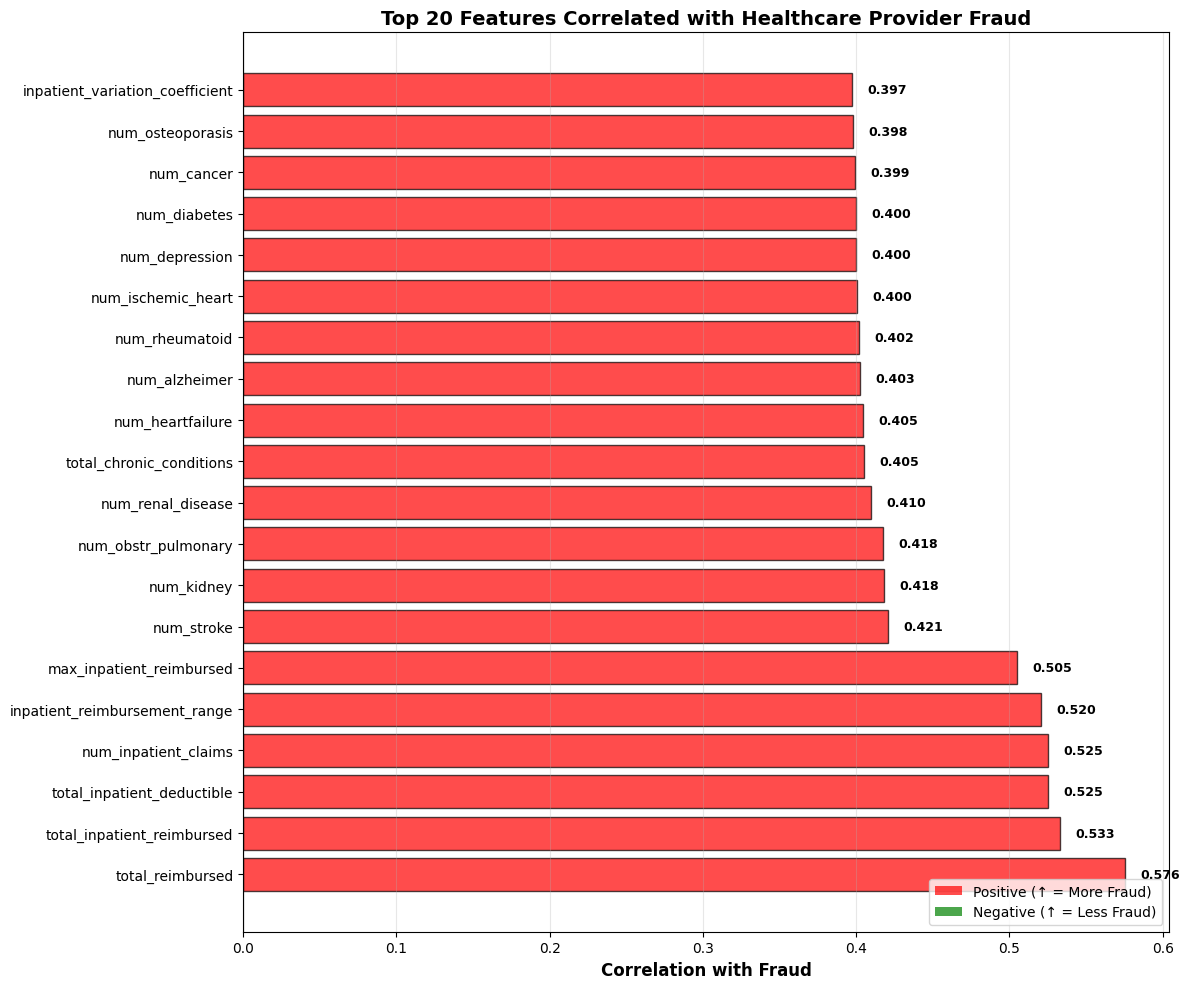

In [51]:
# Visualize top correlations
import matplotlib.pyplot as plt
import seaborn as sns

print("Creating correlation visualization...")

# Get top 20 correlations (absolute value)
top_20_features = correlations.abs().sort_values(ascending=False).head(20)
top_20_correlations = correlations[top_20_features.index]

# Create horizontal bar plot
plt.figure(figsize=(12, 10))
colors = ['red' if x > 0 else 'green' for x in top_20_correlations.values]
bars = plt.barh(range(len(top_20_correlations)), top_20_correlations.values, color=colors, alpha=0.7, edgecolor='black')

plt.yticks(range(len(top_20_correlations)), top_20_correlations.index, fontsize=10)
plt.xlabel('Correlation with Fraud', fontsize=12, fontweight='bold')
plt.title('Top 20 Features Correlated with Healthcare Provider Fraud', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
plt.grid(axis='x', alpha=0.3)

# Add value labels on bars
for i, (bar, val) in enumerate(zip(bars, top_20_correlations.values)):
    plt.text(val + (0.01 if val > 0 else -0.01), bar.get_y() + bar.get_height()/2,
             f'{val:.3f}',
             ha='left' if val > 0 else 'right',
             va='center',
             fontsize=9,
             fontweight='bold')

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='red', alpha=0.7, label='Positive (↑ = More Fraud)'),
                   Patch(facecolor='green', alpha=0.7, label='Negative (↑ = Less Fraud)')]
plt.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/feature_correlations.png',
            dpi=300, bbox_inches='tight')
plt.show()




Creating final comparison visualizations...


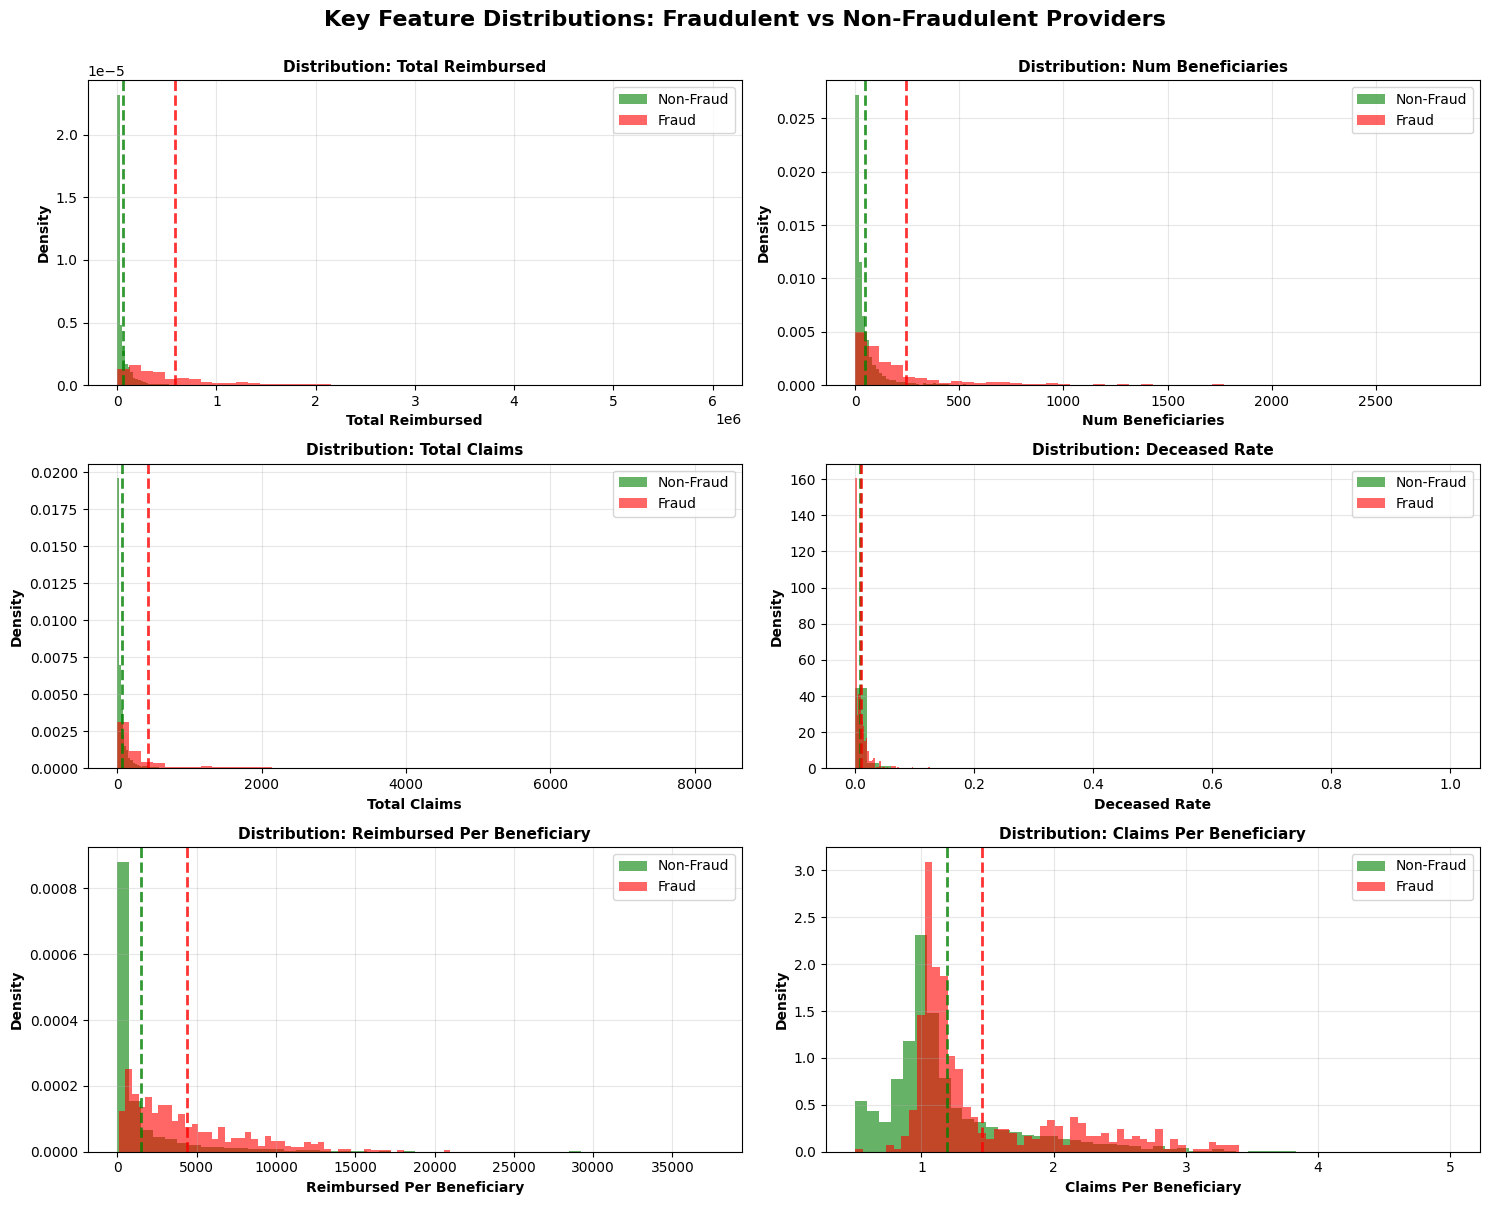


✅ Feature comparison charts saved!


In [52]:
# Create comprehensive comparison visualizations
print("Creating final comparison visualizations...")

# Select key features to compare
key_features = [
    'total_reimbursed',
    'num_beneficiaries',
    'total_claims',
    'deceased_rate',
    'reimbursed_per_beneficiary',
    'claims_per_beneficiary'
]

# Create figure with subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.ravel()

for idx, feature in enumerate(key_features):
    ax = axes[idx]

    # Get data for fraud and non-fraud
    fraud_data = final_data[final_data['PotentialFraud'] == 1][feature]
    non_fraud_data = final_data[final_data['PotentialFraud'] == 0][feature]

    # Create histograms
    ax.hist(non_fraud_data, bins=50, alpha=0.6, label='Non-Fraud', color='green', density=True)
    ax.hist(fraud_data, bins=50, alpha=0.6, label='Fraud', color='red', density=True)

    # Formatting
    ax.set_xlabel(feature.replace('_', ' ').title(), fontweight='bold')
    ax.set_ylabel('Density', fontweight='bold')
    ax.set_title(f'Distribution: {feature.replace("_", " ").title()}', fontweight='bold', fontsize=11)
    ax.legend()
    ax.grid(alpha=0.3)

    # Add mean lines
    ax.axvline(non_fraud_data.mean(), color='green', linestyle='--', linewidth=2, alpha=0.8, label=f'Non-Fraud Mean')
    ax.axvline(fraud_data.mean(), color='red', linestyle='--', linewidth=2, alpha=0.8, label=f'Fraud Mean')

plt.suptitle('Key Feature Distributions: Fraudulent vs Non-Fraudulent Providers',
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/final_feature_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Feature comparison charts saved!")

In [53]:
# Save the processed dataset
print("="*70)
print("💾 SAVING PROCESSED DATASET")
print("="*70)

# Save to CSV
output_path = '/content/drive/MyDrive/fraud_detection_project/data/processed_data.csv'
final_data.to_csv(output_path, index=False)

print(f"\n✅ Dataset saved successfully!")
print(f"   Location: {output_path}")
print(f"   Size: {final_data.shape[0]:,} rows × {final_data.shape[1]} columns")
print(f"   File size: {final_data.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# Verify it was saved
import os
if os.path.exists(output_path):
    print("\n✅ Verification: File exists and is ready for modeling!")
else:
    print("\n❌ ERROR: File was not saved properly!")

💾 SAVING PROCESSED DATASET

✅ Dataset saved successfully!
   Location: /content/drive/MyDrive/fraud_detection_project/data/processed_data.csv
   Size: 5,410 rows × 51 columns
   File size: 2.36 MB

✅ Verification: File exists and is ready for modeling!


In [54]:
# Create comprehensive summary document
print("Creating final summary document...")

summary_doc = f"""
{"="*80}
NOTEBOOK 1: DATA EXPLORATION & FEATURE ENGINEERING - SUMMARY
{"="*80}

PROJECT: Healthcare Provider Fraud Detection
DATE: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}

{"="*80}
1. DATA LOADING
{"="*80}

Original Datasets Loaded:
  • Beneficiary Data: {beneficiary.shape[0]:,} patients × {beneficiary.shape[1]} features
  • Inpatient Data:   {inpatient.shape[0]:,} claims × {inpatient.shape[1]} features
  • Outpatient Data:  {outpatient.shape[0]:,} claims × {outpatient.shape[1]} features
  • Labels:           {labels.shape[0]:,} providers × {labels.shape[1]} features

{"="*80}
2. DATA CLEANING
{"="*80}

Missing Value Handling:
  ✓ Date of Death (DOD): Created 'IsDeceased' binary feature
  ✓ Chronic Conditions: Filled missing with 2 (meaning "No")
  ✓ Renal Disease: Filled missing with '0'
  ✓ Payment Amounts: Filled missing with 0
  ✓ Post-Merge Missing: Filled with 0 (no claims of that type)

{"="*80}
3. FEATURE ENGINEERING
{"="*80}

A. BENEFICIARY FEATURES ({len([c for c in beneficiary_features.columns if c != 'Provider'])} features)
   • Patient counts and demographics
   • Deceased patient statistics
   • Chronic condition prevalence
   • Calculated rates (deceased_rate, male_ratio, etc.)

B. INPATIENT FEATURES ({len([c for c in inpatient_features.columns if c != 'Provider'])} features)
   • Claim counts
   • Reimbursement statistics (sum, mean, std, max, min)
   • Deductible statistics
   • Annual payment patterns

C. OUTPATIENT FEATURES ({len([c for c in outpatient_features.columns if c != 'Provider'])} features)
   • Similar to inpatient features
   • Outpatient-specific patterns

D. ENGINEERED FEATURES (10 additional features)
   • total_claims
   • total_reimbursed
   • avg_reimbursed_per_claim
   • reimbursed_per_beneficiary
   • claims_per_beneficiary
   • inpatient_outpatient_ratio
   • high_chronic_disease_rate
   • variation_coefficient features

TOTAL FEATURES CREATED: {final_data.shape[1] - 2}
(Excluding Provider ID and PotentialFraud target)

{"="*80}
4. FINAL DATASET
{"="*80}

Dimensions: {final_data.shape[0]:,} providers × {final_data.shape[1]} columns

Target Variable Distribution:
  • Non-Fraudulent (0): {(final_data['PotentialFraud'] == 0).sum():,} ({(final_data['PotentialFraud'] == 0).sum() / len(final_data) * 100:.1f}%)
  • Fraudulent (1):     {(final_data['PotentialFraud'] == 1).sum():,} ({(final_data['PotentialFraud'] == 1).sum() / len(final_data) * 100:.1f}%)

Class Imbalance Ratio: {(final_data['PotentialFraud'] == 0).sum() / (final_data['PotentialFraud'] == 1).sum():.1f}:1

Key Statistics:
  • Average claims per provider: {final_data['total_claims'].mean():.1f}
  • Average total reimbursed: ${final_data['total_reimbursed'].mean():,.2f}
  • Average beneficiaries per provider: {final_data['num_beneficiaries'].mean():.1f}
  • Deceased rate: {final_data['deceased_rate'].mean():.2%}

{"="*80}
5. TOP FRAUD INDICATORS (Correlation Analysis)
{"="*80}

Top 10 Features Most Correlated with Fraud:
"""

# Add top correlations
correlations = final_data.drop('Provider', axis=1).corr()['PotentialFraud'].sort_values(ascending=False)
correlations = correlations.drop('PotentialFraud')
top_10 = correlations.head(10)

for i, (feature, corr) in enumerate(top_10.items(), 1):
    summary_doc += f"\n  {i:2d}. {feature:45s} {corr:+.4f}"

summary_doc += f"""

{"="*80}
6. DATA QUALITY
{"="*80}

  ✓ All missing values handled appropriately
  ✓ All features are numeric (ready for modeling)
  ✓ No infinite values
  ✓ Target variable converted to binary (0/1)
  ✓ Data saved for modeling: processed_data.csv

{"="*80}
7. VISUALIZATIONS CREATED
{"="*80}

  ✓ class_distribution.png - Target variable distribution
  ✓ claim_amounts_distribution.png - Claim amount patterns
  ✓ chronic_conditions.png - Chronic condition prevalence
  ✓ claims_per_provider.png - Claim count distributions
  ✓ fraud_comparison.png - Fraud vs non-fraud comparison
  ✓ feature_correlations.png - Feature importance
  ✓ final_feature_comparison.png - Key feature distributions

{"="*80}
8. NEXT STEPS (NOTEBOOK 2)
{"="*80}

  → Load processed_data.csv
  → Split into train/test sets (80/20)
  → Scale features using StandardScaler
  → Handle class imbalance using SMOTE
  → Train multiple models (Logistic Regression, Random Forest, XGBoost)
  → Evaluate and compare models
  → Select best model

{"="*80}
NOTEBOOK 1 COMPLETE! ✅
{"="*80}

Ready for modeling in Notebook 2!
"""

print(summary_doc)

# Save summary
with open('/content/drive/MyDrive/fraud_detection_project/reports/notebook1_summary.txt', 'w') as f:
    f.write(summary_doc)

print("\n✅ Summary document saved to reports folder!")

Creating final summary document...

NOTEBOOK 1: DATA EXPLORATION & FEATURE ENGINEERING - SUMMARY

PROJECT: Healthcare Provider Fraud Detection
DATE: 2025-11-25 17:24:42

1. DATA LOADING

Original Datasets Loaded:
  • Beneficiary Data: 138,556 patients × 25 features
  • Inpatient Data:   40,474 claims × 30 features
  • Outpatient Data:  517,737 claims × 27 features
  • Labels:           5,410 providers × 2 features

2. DATA CLEANING

Missing Value Handling:
  ✓ Date of Death (DOD): Created 'IsDeceased' binary feature
  ✓ Chronic Conditions: Filled missing with 2 (meaning "No")
  ✓ Renal Disease: Filled missing with '0'
  ✓ Payment Amounts: Filled missing with 0
  ✓ Post-Merge Missing: Filled with 0 (no claims of that type)

3. FEATURE ENGINEERING

A. BENEFICIARY FEATURES (20 features)
   • Patient counts and demographics
   • Deceased patient statistics
   • Chronic condition prevalence
   • Calculated rates (deceased_rate, male_ratio, etc.)

B. INPATIENT FEATURES (10 features)
   • Cla

In [55]:


print("="*70)
print("💾 SAVING PROCESSED DATA")
print("="*70)

# Define save path
save_path = '/content/drive/MyDrive/fraud_detection_project/data/processed_data.csv'

# Save the final processed dataset
# (assuming your final dataframe is called 'final_data' - change if different)
final_data.to_csv(save_path, index=False)

print(f"\n✅ Data saved successfully!")
print(f"📍 Location: {save_path}")
print(f"📊 Shape: {final_data.shape}")
print(f"🎯 Features: {final_data.shape[1]}")
print(f"👥 Providers: {final_data.shape[0]}")
print(f"🚨 Fraudulent: {final_data['PotentialFraud'].sum()} ({final_data['PotentialFraud'].mean()*100:.2f}%)")

# Verify the file was created
import os
if os.path.exists(save_path):
    print(f"\n✓ File verified: {os.path.getsize(save_path)/1024/1024:.2f} MB")
else:
    print("\n❌ ERROR: File was not created!")

print("="*70)

💾 SAVING PROCESSED DATA

✅ Data saved successfully!
📍 Location: /content/drive/MyDrive/fraud_detection_project/data/processed_data.csv
📊 Shape: (5410, 51)
🎯 Features: 51
👥 Providers: 5410
🚨 Fraudulent: 506 (9.35%)

✓ File verified: 1.67 MB


In [56]:
# Updated and corrected final checklist
print("="*70)
print("📋 NOTEBOOK 1 - FINAL CHECKLIST (CORRECTED)")
print("="*70)

# More accurate checks
checks = {}

# 1. Data Loading
checks["Data Loading"] = os.path.exists('/content/drive/MyDrive/fraud_detection_project/data/Train_Beneficiarydata.csv')

# 2. Data Cleaning - check that IMPORTANT missing values are handled
# DOD can be missing (means alive), but other important fields should be filled
important_beneficiary_cols = ['ChronicCond_Alzheimer', 'ChronicCond_Heartfailure',
                               'ChronicCond_KidneyDisease', 'ChronicCond_Cancer',
                               'RenalDiseaseIndicator']
beneficiary_cleaned = all([beneficiary_clean[col].isnull().sum() == 0 for col in important_beneficiary_cols if col in beneficiary_clean.columns])

# Check that IsDeceased column was created
has_deceased_column = 'IsDeceased' in beneficiary_clean.columns

checks["Data Cleaning"] = beneficiary_cleaned and has_deceased_column

# 3. Feature Engineering
checks["Feature Engineering"] = final_data.shape[1] > 50

# 4. Target Conversion
checks["Target Conversion"] = final_data['PotentialFraud'].dtype in ['int64', 'int32']

# 5. Processed Data Saved
checks["Processed Data Saved"] = os.path.exists('/content/drive/MyDrive/fraud_detection_project/data/processed_data.csv')

# 6. Visualizations Created
results_path = '/content/drive/MyDrive/fraud_detection_project/results/'
if os.path.exists(results_path):
    viz_count = len([f for f in os.listdir(results_path) if f.endswith('.png')])
    checks["Visualizations Created"] = viz_count >= 5
else:
    checks["Visualizations Created"] = False

# 7. Summary Documentation
checks["Summary Documentation"] = os.path.exists('/content/drive/MyDrive/fraud_detection_project/reports/notebook1_summary.txt')

print("\nTask Completion Status:\n")
for task, completed in checks.items():
    status = "✅" if completed else "❌"
    print(f"{status} {task}")

# Additional verification
print("\n" + "="*70)
print("DETAILED VERIFICATION:")
print("="*70)

print(f"\n✓ Beneficiary data has IsDeceased column: {has_deceased_column}")
print(f"✓ Chronic conditions cleaned: {beneficiary_cleaned}")
print(f"✓ Final dataset shape: {final_data.shape}")
print(f"✓ Target is numeric: {final_data['PotentialFraud'].dtype}")
print(f"✓ No missing values in final data: {final_data.isnull().sum().sum() == 0}")

all_complete = all(checks.values())

print("\n" + "="*70)
if all_complete:
    print("🎉 CONGRATULATIONS! NOTEBOOK 1 IS COMPLETE!")
    print("="*70)
    print("\nYou have successfully:")
    print("  ✓ Loaded and explored healthcare fraud data")
    print("  ✓ Cleaned and handled missing values appropriately")
    print("  ✓ Created comprehensive provider-level features")
    print("  ✓ Generated insightful visualizations")
    print("  ✓ Documented all your work")
    print(f"\n📊 Final Dataset: {final_data.shape[0]:,} providers × {final_data.shape[1]} features")
    print(f"💾 Saved to: processed_data.csv")
    print("\n🚀 You are ready to move to NOTEBOOK 2: MODELING!")
else:
    print("⚠️ SOME TASKS INCOMPLETE")
    print("="*70)
    print("\nPlease review the tasks marked with ❌")

    # Show which tasks failed
    failed_tasks = [task for task, status in checks.items() if not status]
    if failed_tasks:
        print("\nFailed tasks:")
        for task in failed_tasks:
            print(f"  ❌ {task}")

📋 NOTEBOOK 1 - FINAL CHECKLIST (CORRECTED)

Task Completion Status:

✅ Data Loading
✅ Data Cleaning
✅ Feature Engineering
✅ Target Conversion
✅ Processed Data Saved
✅ Visualizations Created
✅ Summary Documentation

DETAILED VERIFICATION:

✓ Beneficiary data has IsDeceased column: True
✓ Chronic conditions cleaned: True
✓ Final dataset shape: (5410, 51)
✓ Target is numeric: int64
✓ No missing values in final data: True

🎉 CONGRATULATIONS! NOTEBOOK 1 IS COMPLETE!

You have successfully:
  ✓ Loaded and explored healthcare fraud data
  ✓ Cleaned and handled missing values appropriately
  ✓ Created comprehensive provider-level features
  ✓ Generated insightful visualizations
  ✓ Documented all your work

📊 Final Dataset: 5,410 providers × 51 features
💾 Saved to: processed_data.csv

🚀 You are ready to move to NOTEBOOK 2: MODELING!
